# Invoice Payment Risk Detection — End-Term Notebook
CSL236 — Introduction to Artificial Intelligence and Machine Learning  
The NorthCap University | Semester 5 | Group AI 6  
**Students:** Chaitali — 24csu246; Vanshika — **[fill in roll number]**  
**Faculty:** Dr Poonam

We predict whether an invoice will be paid late (classification) and how many days overdue it will be (regression). The prototype supports follow-up decisions for a company's known customers. It does not predict permanent non-payment: every invoice in this dataset was settled.

### How to read this notebook
Each stage explains the question, method, output and conclusion. Code-generated interpretations below tables describe the actual run. Older results are labelled historical and are not passed off as newly tuned results.

Run from top to bottom with **Restart Kernel and Run All**. The CSV should be beside this notebook, or attached as a Kaggle dataset. If missing, the loading cell tries the public Kaggle download. Internet is needed only for missing packages/data. No GPU is needed. All model-export/Joblib/ZIP cells have been removed as requested.

### Requirement checklist
| Requirement | Where covered |
|---|---|
| Names, roll numbers and title | This cell; complete Vanshika's roll number before submission |
| Dataset description | Section 1 and data dictionary |
| Preprocessing | Quality checks, encoding, imputation, scaling and pipelines |
| Visualisations and interpretations | EDA, comparison plots, ROC/PR, confusion matrices, residuals and lift |
| One feature-selection method | VarianceThreshold, fitted inside training folds; counts and removed features printed |
| At least 3 regression techniques | Ridge, Random Forest and Gradient Boosting, plus median baseline |
| At least 3 classification techniques | Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, XGBoost, plus dummy baseline |
| At least 3 classification measures | Precision, recall, F1, accuracy, ROC-AUC and average precision |
| GridSearchCV / RandomizedSearchCV | GridSearchCV for all five classifier families and all three regressors |

### What was preserved and corrected
The original data checks, distributions, binning, statistical tests, customer history, correlation analysis, A/B feature comparison, imbalance experiments, time-split comparison, dispute ablation, importance, ROC/PR, confusion matrices, threshold/lift analysis and three regression families are retained in this organised workflow. Duplicate regression cells were consolidated. Pre-encoded full-data cross-validation was replaced with fold-fitted pipelines. History is evaluated with chronological folds, not shuffled future-to-past evaluation. The old deployment results are kept as a labelled reference at the end.

This is assisted revision of our existing notebook. We must review the explanations, cite sources and follow our institution's disclosure rules. A Turnitin similarity or AI-detection percentage cannot be guaranteed. No results are invented or adjusted to meet a desired score.

## 0. Setup
We use pandas/NumPy for data, SciPy for statistical tests, scikit-learn for preprocessing and models, XGBoost for boosted trees, and imbalanced-learn for a separate SMOTE experiment. A seed of 42 makes random choices reproducible; it does not improve accuracy. Different library versions can change results slightly.

If imports fail, run the following command in a separate notebook cell, then restart the kernel:
```python
%pip install pandas numpy scipy matplotlib seaborn 'scikit-learn>=1.4,<1.9' 'xgboost>=2,<4' 'imbalanced-learn>=0.14,<0.15'
```

In [1]:
import os, time, json, platform, hashlib, importlib.metadata, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.special import expit
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, StratifiedKFold, cross_validate, ParameterGrid
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, make_scorer, roc_curve,
    precision_recall_curve, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
SEED = RANDOM_STATE = 42
N_JOBS = 2
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
FIG_DIR = Path('figures_endterm'); FIG_DIR.mkdir(exist_ok=True)
def save_fig(name):
    plt.savefig(FIG_DIR / (name + '.png'), dpi=120, bbox_inches='tight')
def explain(text): display(Markdown('**Output and conclusion:** ' + text))
print('Python:', platform.python_version())
versions = {p: importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','xgboost','imbalanced-learn']}
display(pd.Series(versions, name='version').to_frame())

Python: 3.12.14


,version
numpy,2.3.5
pandas,2.2.3
scipy,1.17.0
scikit-learn,1.8.0
xgboost,3.4.1
imbalanced-learn,0.14.2


## 1. Dataset description and loading
We use **Finance Factoring – IBM Late Payment Histories**, file `WA_Fn-UseC_-Accounts-Receivable.csv`, from https://www.kaggle.com/datasets/hhenry/finance-factoring-ibm-late-payment-histories . We treat this as sample/synthetic data for an academic prototype; it is not evidence of real-company deployment performance.

The original file has 2,466 invoices, 12 columns, 100 customers and 5 country codes, with invoice dates in 2012–2013. Amounts are in unspecified dataset units. We retain an unchanged `df_raw` and use `df` for analysis. The checksum identifies the exact file used.

In [2]:
CSV_NAME = 'WA_Fn-UseC_-Accounts-Receivable.csv'
candidates = [Path(CSV_NAME), Path('/content') / CSV_NAME]
if Path('/kaggle/input').exists(): candidates += list(Path('/kaggle/input').rglob(CSV_NAME))
DATA_FILE = next((p for p in candidates if p.exists()), None)
if DATA_FILE is None:
    import urllib.request, zipfile, io
    url = 'https://www.kaggle.com/api/v1/datasets/download/hhenry/finance-factoring-ibm-late-payment-histories'
    try:
        with urllib.request.urlopen(url, timeout=60) as response:
            archive = zipfile.ZipFile(io.BytesIO(response.read()))
        member = next(n for n in archive.namelist() if Path(n).name == CSV_NAME)
        DATA_FILE = Path(CSV_NAME); DATA_FILE.write_bytes(archive.read(member))
    except Exception as exc:
        raise FileNotFoundError('Attach the Kaggle dataset or place the original CSV beside this notebook, then rerun.') from exc
df_raw = pd.read_csv(DATA_FILE)
df = df_raw.copy()
print('File:', DATA_FILE)
print('SHA256:', hashlib.sha256(DATA_FILE.read_bytes()).hexdigest())
print('Rows, columns:', df.shape)
display(df.head())

File: WA_Fn-UseC_-Accounts-Receivable.csv
SHA256: 651bc4225708bf33148a0e177c9221afdf697d3a4de10333725a4af3dd022fcf
Rows, columns: (2466, 12)


,countryCode,customerID,PaperlessDate,invoiceNumber,InvoiceDate,DueDate,InvoiceAmount,Disputed,SettledDate,PaperlessBill,DaysToSettle,DaysLate
0,391,0379-NEVHP,4/6/2013,611365,1/2/2013,2/1/2013,55.94,No,1/15/2013,Paper,13,0
1,406,8976-AMJEO,3/3/2012,7900770,1/26/2013,2/25/2013,61.74,Yes,3/3/2013,Electronic,36,6
2,391,2820-XGXSB,1/26/2012,9231909,7/3/2013,8/2/2013,65.88,No,7/8/2013,Electronic,5,0
3,406,9322-YCTQO,4/6/2012,9888306,2/10/2013,3/12/2013,105.92,No,3/17/2013,Electronic,35,5
4,818,6627-ELFBK,11/26/2012,15752855,10/25/2012,11/24/2012,72.27,Yes,11/28/2012,Paper,34,4


# Part 1 — Data understanding & cleaning checks

### 1.1 Column dictionary (what each column means)

| # | Column | Meaning | Known when the invoice is issued? |
|---|---|---|---|
| 1 | `countryCode` | Customer's country/region code (5 codes) | ✅ yes |
| 2 | `customerID` | Unique customer identifier (100 customers) | ✅ yes |
| 3 | `PaperlessDate` | Recorded date associated with paperless billing | Availability needs checking; excluded |
| 4 | `invoiceNumber` | Unique invoice ID (just a label, no predictive meaning) | ✅ but useless (ID) |
| 5 | `InvoiceDate` | Date the invoice was issued | ✅ yes |
| 6 | `DueDate` | Payment deadline | ✅ yes |
| 7 | `InvoiceAmount` | Billed amount | ✅ yes |
| 8 | `Disputed` | Was the invoice disputed? (Yes/No) | ⚠️ *maybe* – disputes can arise after issuing |
| 9 | `SettledDate` | Date it was actually paid | ❌ **outcome** |
| 10 | `PaperlessBill` | Electronic or Paper bill | ✅ yes |
| 11 | `DaysToSettle` | Days from invoice date to payment | ❌ **outcome** |
| 12 | `DaysLate` | Days paid after the due date (0 = on time) | ❌ **outcome – this is our target source** |

The ❌ columns describe what *happened after* the invoice was issued. Using them to predict lateness would be **data leakage** (cheating). We will keep them for EDA but exclude them from models.

### 1.2 Data types & summary statistics
`df.dtypes` shows the type of each column; `df.describe()` gives count/mean/std/min/quartiles/max for numbers; `describe(include='object')` does the same for text columns (count, unique values, most frequent value).

In [3]:
print(df.dtypes)

countryCode        int64
customerID        object
PaperlessDate     object
invoiceNumber      int64
InvoiceDate       object
DueDate           object
InvoiceAmount    float64
Disputed          object
SettledDate       object
PaperlessBill     object
DaysToSettle       int64
DaysLate           int64
dtype: object


In [4]:
df.describe()

Out[4]: 
       countryCode  invoiceNumber  InvoiceAmount  DaysToSettle     DaysLate
count  2466.000000   2.466000e+03    2466.000000    2466.00000  2466.000000
mean    620.446067   4.978431e+09      59.895856      26.44485     3.442417
std     215.933610   2.884272e+09      20.435838      12.33493     6.290607
min     391.000000   6.113650e+05       5.260000       0.00000     0.000000
25%     406.000000   2.528854e+09      46.400000      18.00000     0.000000
50%     770.000000   4.964228e+09      60.560000      26.00000     0.000000
75%     818.000000   7.494512e+09      73.765000      35.00000     5.000000
max     897.000000   9.990244e+09     128.280000      75.00000    45.000000


In [5]:
df.describe(include="object")

Out[5]: 
        customerID PaperlessDate InvoiceDate    DueDate Disputed SettledDate  \
count         2466          2466        2466       2466     2466        2466   
unique         100            91         681        681        2         695   
top     9149-MATVB      3/3/2012   8/22/2013  9/21/2013       No   4/28/2013   
freq            36            58          10         10     1905          10   

       PaperlessBill  
count           2466  
unique             2  
top            Paper  
freq            1263  


### 1.3 Convert dates & numbers to proper types
Dates arrive as plain text (`'4/6/2013'`). `pd.to_datetime` turns them into real dates so we can subtract them and extract month/weekday. The format `%m/%d/%Y` means *month/day/year* (US style).
`pd.to_numeric(..., errors='coerce')` makes sure the amount is a number (anything unreadable becomes `NaN` instead of crashing).

In [6]:
date_cols = ["PaperlessDate", "InvoiceDate", "DueDate", "SettledDate"]
for c in date_cols:
    df[c] = pd.to_datetime(df[c], format="%m/%d/%Y", errors="coerce")

df["InvoiceAmount"] = pd.to_numeric(df["InvoiceAmount"], errors="coerce")

print("Dates unreadable (should be 0):", int(df[date_cols].isna().sum().sum()))
print("Invoice period:", df["InvoiceDate"].min().date(), "→", df["InvoiceDate"].max().date())

Dates unreadable (should be 0): 0
Invoice period: 2012-01-03 → 2013-12-02


### 1.4 Duplicates & missing values
* **Duplicates** – identical rows would double-count information.
* **Missing values** – gaps that models cannot handle directly.

In [7]:
quality = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing_count': df.isna().sum(), 'missing_percent': 100*df.isna().mean()})
display(quality)
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate invoice IDs:', df.invoiceNumber.duplicated().sum())
print('Numerical columns:', df.select_dtypes(include=np.number).columns.tolist())
print('Categorical/text columns:', df.select_dtypes(include=['object','string']).columns.tolist())
explain('No missing original values means we do not need to invent values or drop complete rows. Later engineered histories can be missing for first-time customers; those are imputed inside each training fold. Country codes and invoice IDs are semantically categories/identifiers even if stored as numbers.')

Duplicate rows: 0
Duplicate invoice IDs: 0
Numerical columns: ['countryCode', 'invoiceNumber', 'InvoiceAmount', 'DaysToSettle', 'DaysLate']
Categorical/text columns: ['customerID', 'Disputed', 'PaperlessBill']


,dtype,missing_count,missing_percent
countryCode,int64,0,0.0
customerID,object,0,0.0
PaperlessDate,datetime64[ns],0,0.0
invoiceNumber,int64,0,0.0
InvoiceDate,datetime64[ns],0,0.0
DueDate,datetime64[ns],0,0.0
InvoiceAmount,float64,0,0.0
Disputed,object,0,0.0
SettledDate,datetime64[ns],0,0.0
PaperlessBill,object,0,0.0


**Output and conclusion:** No missing original values means we do not need to invent values or drop complete rows. Later engineered histories can be missing for first-time customers; those are imputed inside each training fold. Country codes and invoice IDs are semantically categories/identifiers even if stored as numbers.

### 1.5 Logic checks (is the data internally consistent?)
We verify that the columns agree with each other:
* `DaysToSettle` should equal `SettledDate − InvoiceDate`
* `DaysLate` should equal `max(SettledDate − DueDate, 0)`
* The payment term (`DueDate − InvoiceDate`) — is it always the same?

In [8]:
check_settle = (df["SettledDate"] - df["InvoiceDate"]).dt.days == df["DaysToSettle"]
check_late   = (df["SettledDate"] - df["DueDate"]).dt.days.clip(lower=0) == df["DaysLate"]
df["payment_terms_days"] = (df["DueDate"] - df["InvoiceDate"]).dt.days

print("DaysToSettle consistent :", check_settle.all())
print("DaysLate consistent     :", check_late.all())
print("Payment terms (days)    :", df["payment_terms_days"].unique())

DaysToSettle consistent : True
DaysLate consistent     : True
Payment terms (days)    : [30]


**Findings:** the data is clean (no duplicates, no missing values, columns agree).
Every invoice has exactly **30 days** of payment terms, so "payment terms" carries no information and is useless as a feature.

# Part 2 — The target variable

We turn the problem into a **binary classification**:

* `late_payment = 1` if `DaysLate > 0` (paid after the due date)
* `late_payment = 0` otherwise (paid on time)

We also create `late_bucket`, a more detailed severity label (used only for EDA charts).

late_payment
On time    1589
Late        877
Name: count, dtype: int64

Late-payment rate: 35.6%


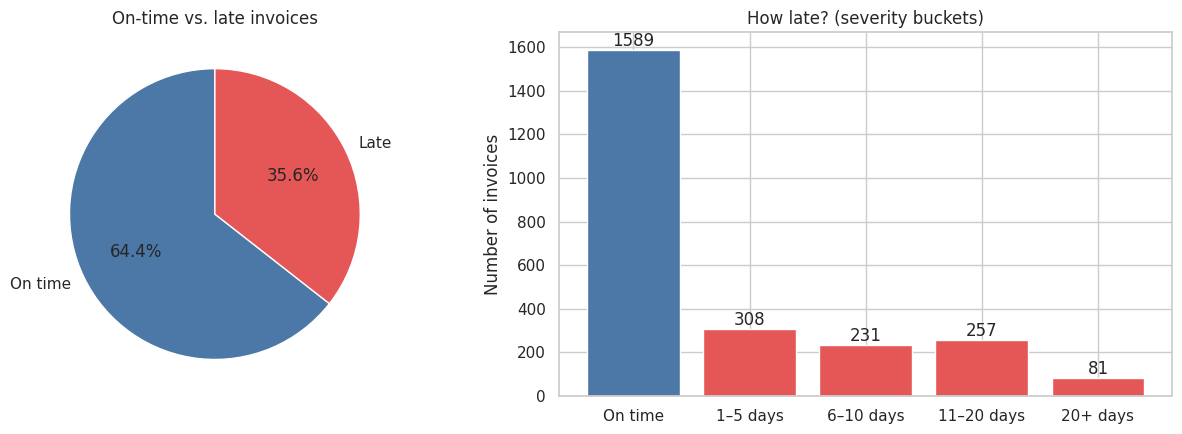

In [9]:
df["late_payment"] = (df["DaysLate"] > 0).astype(int)
df["late_bucket"] = pd.cut(df["DaysLate"], bins=[-1, 0, 5, 10, 20, np.inf],
                           labels=["On time", "1–5 days", "6–10 days", "11–20 days", "20+ days"])

counts = df["late_payment"].value_counts().sort_index()
print(counts.rename({0: "On time", 1: "Late"}))
print(f"\nLate-payment rate: {df['late_payment'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].pie(counts.values, labels=["On time", "Late"], autopct="%1.1f%%",
            colors=["#4C78A8", "#E45756"], startangle=90, wedgeprops={"edgecolor": "white"})
axes[0].set_title("On-time vs. late invoices")

bucket_counts = df["late_bucket"].value_counts().sort_index()
bars = axes[1].bar(bucket_counts.index.astype(str), bucket_counts.values,
                   color=["#4C78A8"] + ["#E45756"] * 4)
axes[1].bar_label(bars)
axes[1].set_title("How late? (severity buckets)")
axes[1].set_ylabel("Number of invoices")
plt.tight_layout(); save_fig("01_target_distribution"); plt.show()

**Output and meaning:** 877 of 2,466 invoices are late (35.6%). This is moderate imbalance, so we compare ordinary training, class weights and an exploratory SMOTE experiment. It is not necessary to make the class counts equal. The bins are domain-defined delay ranges for interpretation, not training targets for a multiclass model. All invoices were settled; late payment is not permanent default.

# Part 3 — EDA: single variables (univariate)

### 3.1 Distributions of the numeric columns
**Histogram** = bar chart of how often values occur (bars = value ranges). The smooth line (KDE) is a smoothed version of the histogram.
**Boxplot** = the box shows the middle 50% of values (Q1–Q3), the line inside is the median, the "whiskers" are the normal range and the dots beyond are statistical *outliers*.

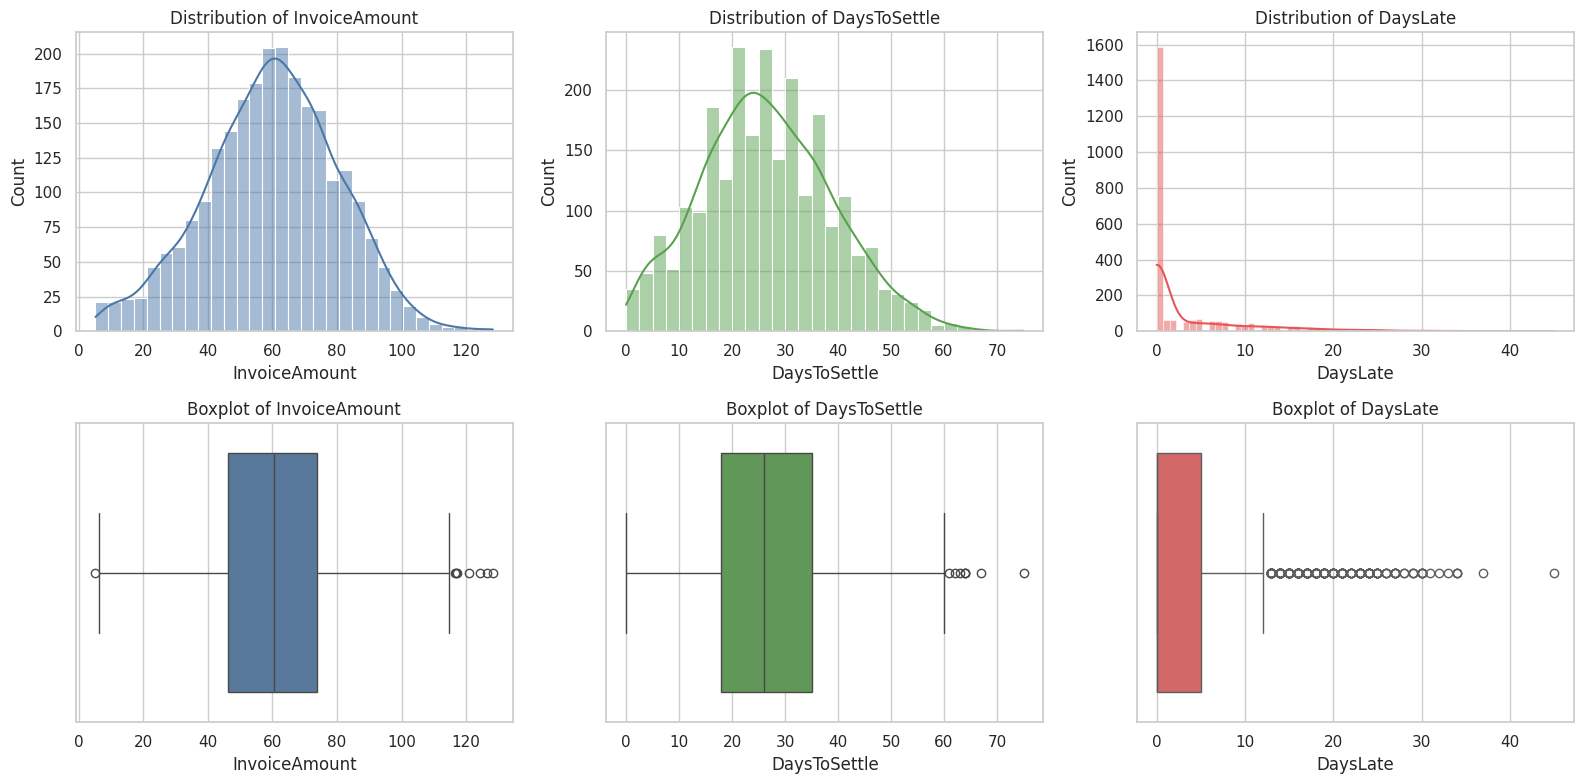

In [10]:
num_cols = ["InvoiceAmount", "DaysToSettle", "DaysLate"]
colors = ["#4C78A8", "#59A14F", "#E45756"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, (col, color) in enumerate(zip(num_cols, colors)):
    sns.histplot(df[col], kde=True, ax=axes[0, i], color=color)
    axes[0, i].set_title(f"Distribution of {col}")
    sns.boxplot(x=df[col], ax=axes[1, i], color=color)
    axes[1, i].set_title(f"Boxplot of {col}")
plt.tight_layout(); save_fig("02_numeric_distributions"); plt.show()

### 3.2 Outlier count (IQR rule)
IQR rule: anything below `Q1 − 1.5·IQR` or above `Q3 + 1.5·IQR` is flagged as an outlier (IQR = Q3 − Q1).

In [11]:
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[col] < low) | (df[col] > high)).sum())
    rows.append({"column": col, "lower_bound": round(low, 2), "upper_bound": round(high, 2),
                 "outliers": n_out, "outliers_%": round(100 * n_out / len(df), 2)})
pd.DataFrame(rows)

Out[11]: 
          column  lower_bound  upper_bound  outliers  outliers_%
0  InvoiceAmount         5.35       114.81         8        0.32
1   DaysToSettle        -7.50        60.50         8        0.32
2       DaysLate        -7.50        12.50       259       10.50


**Output and conclusion:** The amount distribution is roughly symmetric, so we keep its scale information and standardise it for linear models rather than force a log transformation. IQR flags 8 amounts, 8 settlement durations and 259 delays. A statistical flag is not proof of an error. We retain these records because long delays are relevant; this does not independently verify every unusual record. Targets are excluded from input features.

### 3.3 Categorical columns
Bar charts counting how many invoices fall into each category.

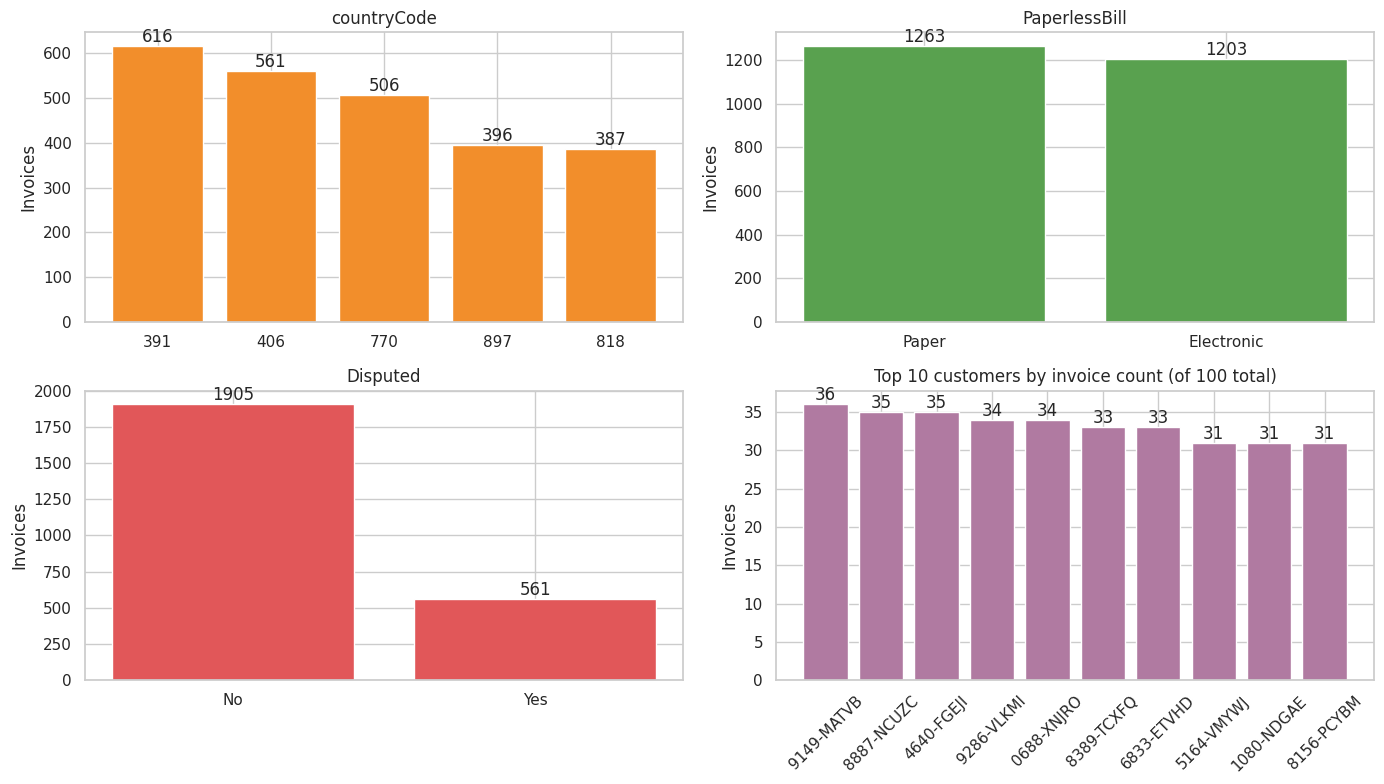

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (col, color) in zip(axes.ravel(), [("countryCode", "#F28E2B"), ("PaperlessBill", "#59A14F"),
                                          ("Disputed", "#E15759"), ("customerID", "#B07AA1")]):
    vc = df[col].value_counts()
    if col == "customerID":
        vc = vc.head(10)
        ax.set_title(f"Top 10 customers by invoice count (of {df[col].nunique()} total)")
    else:
        ax.set_title(f"{col}")
    bars = ax.bar(vc.index.astype(str), vc.values, color=color)
    ax.bar_label(bars)
    ax.set_ylabel("Invoices")
    ax.tick_params(axis="x", rotation=45 if col == "customerID" else 0)
plt.tight_layout(); save_fig("03_categorical_counts"); plt.show()

**Findings:** 5 country codes with fairly balanced volumes; ~100 customers with 15–36 invoices each; `Disputed = Yes` is a minority (about 23% of invoices, 561 rows) — useful for descriptive comparisons, but association does not establish causation.

# Part 4 — EDA: each variable vs. late payment (bivariate)

Here we ask: **do late invoices look different from on-time ones?** The dashed line in each chart is the overall late rate (≈36%); bars above it are riskier than average. `n=` shows how many invoices stand behind each bar (small n = less reliable).

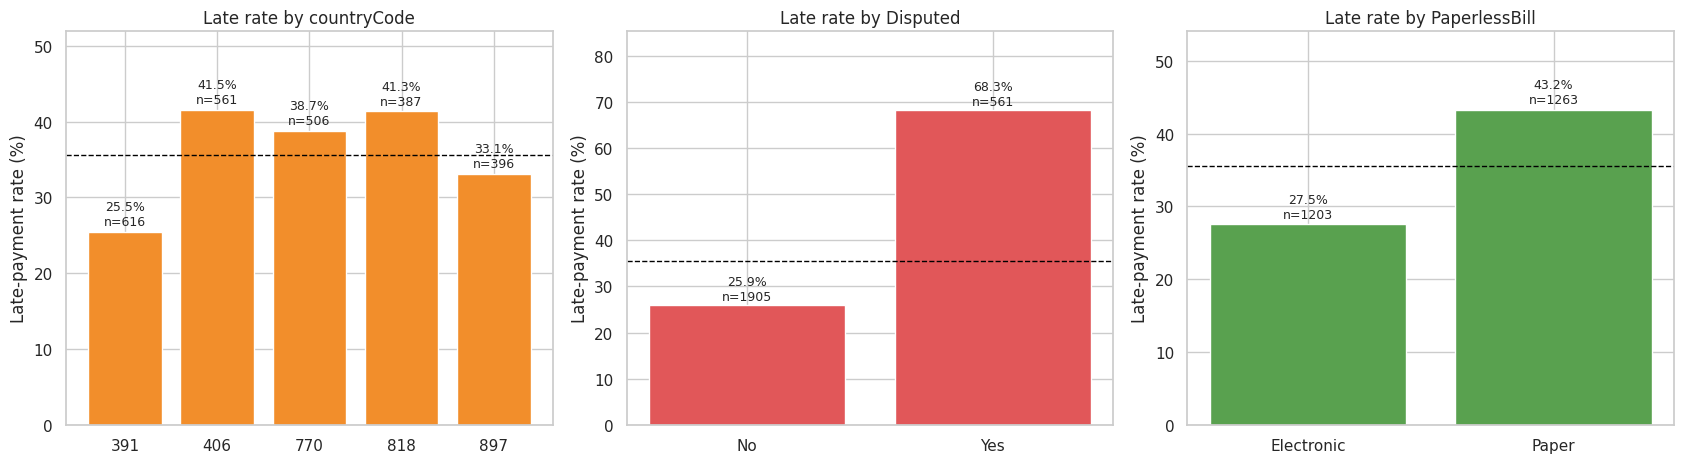

In [13]:
overall = df["late_payment"].mean()

def late_rate_bar(col, ax, order=None, color="#4C78A8", title=None):
    # Draws the late-payment rate for each category of `col`.
    g = df.groupby(col)["late_payment"].agg(["mean", "count"]).reset_index()
    if order is not None:
        g = g.set_index(col).loc[order].reset_index()
    bars = ax.bar(g[col].astype(str), g["mean"] * 100, color=color)
    for b, (_, r) in zip(bars, g.iterrows()):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5,
                f"{r['mean']:.1%}\nn={int(r['count'])}", ha="center", va="bottom", fontsize=9)
    ax.axhline(overall * 100, color="black", ls="--", lw=1)
    ax.set_ylabel("Late-payment rate (%)")
    ax.set_title(title or f"Late rate by {col}")
    ax.set_ylim(0, max(g["mean"]) * 100 * 1.25)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
late_rate_bar("countryCode", axes[0], color="#F28E2B")
late_rate_bar("Disputed", axes[1], color="#E15759")
late_rate_bar("PaperlessBill", axes[2], color="#59A14F")
plt.tight_layout(); save_fig("04_late_rate_by_category"); plt.show()

**Findings**
* **Disputed** invoices are late far more often than undisputed ones — the strongest single signal so far (but see the leakage caution in Part 5).
* **Paper** bills are paid late more often than **Electronic** ones.
* **Country** matters too: some countries have noticeably higher late rates than others.

### 4.1 Invoice amount vs. lateness
Two views: (left) amount distribution for on-time vs late invoices; (right) late rate in 5 equal-sized amount groups (quintiles).

<ipython-input-14-db855c650206>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="late_payment", y="InvoiceAmount", ax=axes[0],
<ipython-input-13-3c2dda7aa307>:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = df.groupby(col)["late_payment"].agg(["mean", "count"]).reset_index()


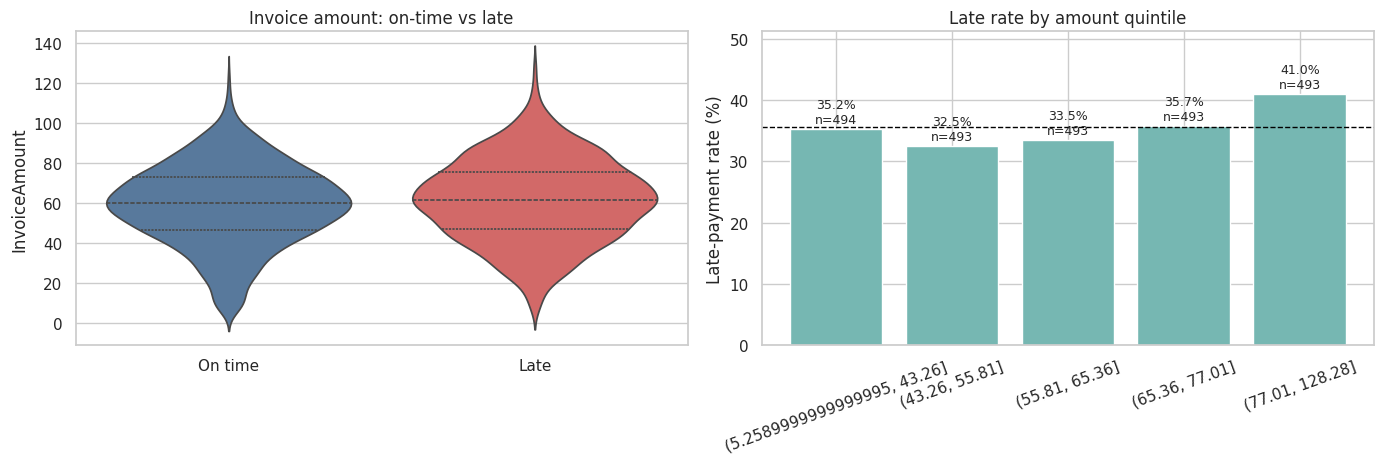

In [14]:
df["amount_band"] = pd.qcut(df["InvoiceAmount"], 5)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.violinplot(data=df, x="late_payment", y="InvoiceAmount", ax=axes[0],
               palette=["#4C78A8", "#E45756"], inner="quartile")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["On time", "Late"])
axes[0].set_xlabel(""); axes[0].set_title("Invoice amount: on-time vs late")

late_rate_bar("amount_band", axes[1], color="#76B7B2", title="Late rate by amount quintile")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); save_fig("05_amount_vs_late"); plt.show()

**Findings:** amount separates late from on-time payers only weakly — the two violins overlap almost completely. The late rate is similar (~33–36%) across the lower four quintiles and only a bit higher (~41%) for the largest invoices. Invoice size is **not** a strong driver.

### 4.2 Time patterns
Does *when* the invoice is issued matter? (month trend, day of week, calendar month)

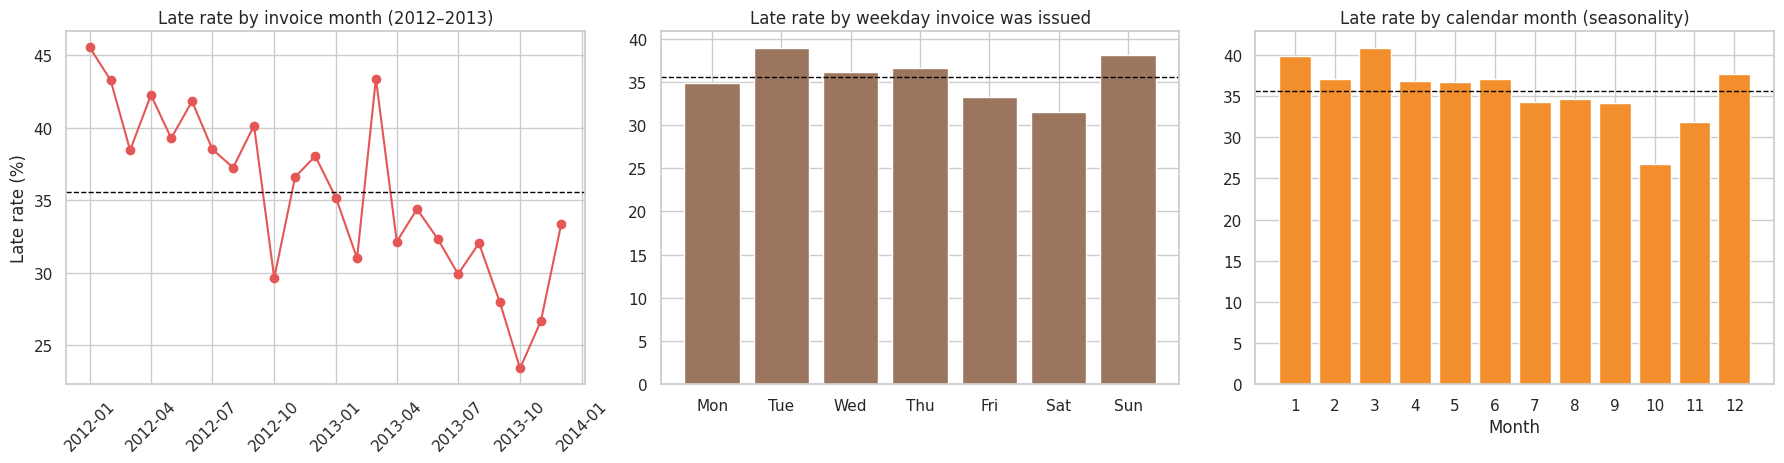

In [15]:
df["inv_month"] = df["InvoiceDate"].dt.month
df["inv_dow"]   = df["InvoiceDate"].dt.dayofweek            # 0 = Monday ... 6 = Sunday
df["inv_ym"]    = df["InvoiceDate"].dt.to_period("M").dt.to_timestamp()

monthly = df.groupby("inv_ym")["late_payment"].agg(["mean", "count"])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].plot(monthly.index, monthly["mean"] * 100, marker="o", color="#E45756")
axes[0].axhline(overall * 100, color="black", ls="--", lw=1)
axes[0].set_title("Late rate by invoice month (2012–2013)"); axes[0].set_ylabel("Late rate (%)")
axes[0].tick_params(axis="x", rotation=45)

dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
g = df.groupby("inv_dow")["late_payment"].mean() * 100
axes[1].bar([dow_names[i] for i in g.index], g.values, color="#9C755F")
axes[1].axhline(overall * 100, color="black", ls="--", lw=1)
axes[1].set_title("Late rate by weekday invoice was issued")

g = df.groupby("inv_month")["late_payment"].mean() * 100
axes[2].bar(g.index.astype(str), g.values, color="#F28E2B")
axes[2].axhline(overall * 100, color="black", ls="--", lw=1)
axes[2].set_title("Late rate by calendar month (seasonality)"); axes[2].set_xlabel("Month")
plt.tight_layout(); save_fig("06_time_patterns"); plt.show()

**Findings:** there is a **mild downward drift** — the late rate falls from roughly 40–45% in early 2012 to about 25–33% in late 2013 (the observed late-payment rate changed over time; its cause is not established). Weekday and calendar month show no consistent pattern, so those features are expected to add little. (The final month, Dec 2013, has only 9 invoices, so its rate is noisy.)
This drift also matters later: in the time-based test (Part 6.9) the test period has a lower late rate than the training period.

### 4.3 Customer behaviour — the hidden driver?
Each customer has ~25 invoices. If every customer had the *same* chance of paying late, customer late-rates would only vary by random luck. Let's check whether the real spread is larger than luck would give — if so, **who the customer is** matters a lot.

Observed std-dev of customer late rates : 0.335
Std-dev expected from pure chance       : 0.096
Customers who are NEVER late            : 17
Customers late on >60% of invoices      : 28


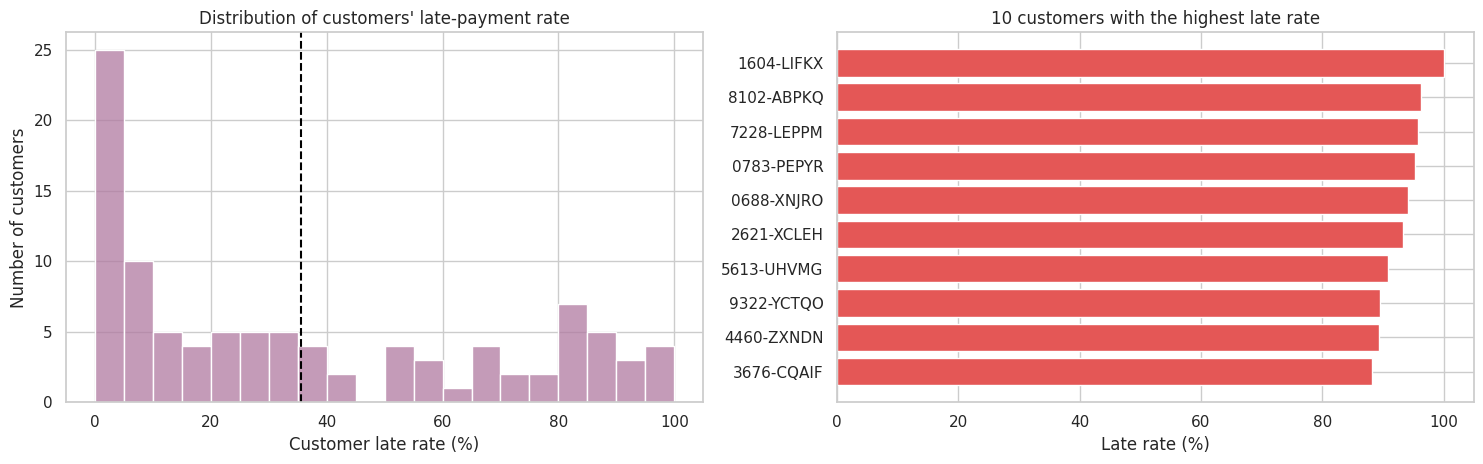

In [16]:
cust = df.groupby("customerID")["late_payment"].agg(late_rate="mean", invoices="count")
p, n_avg = overall, cust["invoices"].mean()
expected_sd = np.sqrt(p * (1 - p) / n_avg)          # spread we'd see by pure chance (binomial)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.histplot(cust["late_rate"] * 100, bins=20, color="#B07AA1", ax=axes[0])
axes[0].axvline(overall * 100, color="black", ls="--")
axes[0].set_title("Distribution of customers' late-payment rate")
axes[0].set_xlabel("Customer late rate (%)"); axes[0].set_ylabel("Number of customers")

top = cust.sort_values("late_rate", ascending=False).head(10)
axes[1].barh(top.index[::-1], top["late_rate"][::-1] * 100, color="#E45756")
axes[1].set_title("10 customers with the highest late rate"); axes[1].set_xlabel("Late rate (%)")
plt.tight_layout(); save_fig("07_customer_behaviour"); plt.show()

print(f"Observed std-dev of customer late rates : {cust['late_rate'].std():.3f}")
print(f"Std-dev expected from pure chance       : {expected_sd:.3f}")
print(f"Customers who are NEVER late            : {(cust['late_rate'] == 0).sum()}")
print(f"Customers late on >60% of invoices      : {(cust['late_rate'] > 0.6).sum()}")

**Interpretation:** Customers differ substantially in their observed late-payment rates. This motivates testing customer identity and historical behaviour as predictors. It does not prove that their habits will stay the same. The no-history case needs separate handling, and generalisation to new customers is not established.

### 4.4 How late are late invoices?
Restricting to late invoices only: the distribution of `DaysLate` (the regressors later predict days overdue across all invoices, including zeros; this chart looks only at the late subset).

count    877.00
mean       9.68
std        7.14
min        1.00
25%        4.00
50%        8.00
75%       14.00
max       45.00
Name: DaysLate, dtype: float64


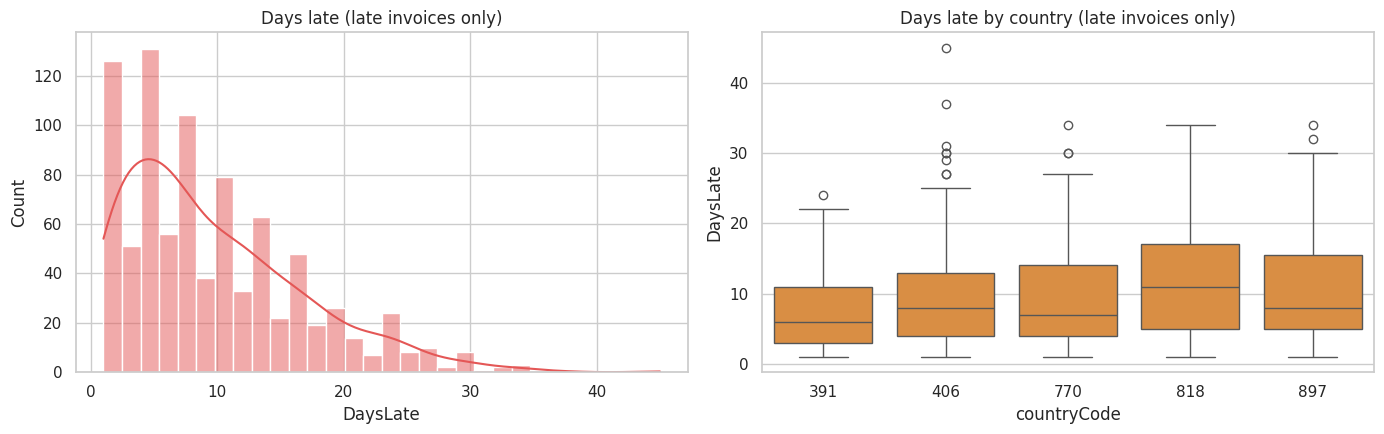

In [17]:
late_only = df[df["DaysLate"] > 0]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(late_only["DaysLate"], bins=30, kde=True, color="#E45756", ax=axes[0])
axes[0].set_title("Days late (late invoices only)")
sns.boxplot(data=late_only, x="countryCode", y="DaysLate", color="#F28E2B", ax=axes[1])
axes[1].set_title("Days late by country (late invoices only)")
plt.tight_layout(); save_fig("08_days_late_among_late"); plt.show()
print(late_only["DaysLate"].describe().round(2))

### 4.5 Country × Disputed / Paperless (two factors together)
Heatmap cells show the late rate for each combination. Darker red = riskier.

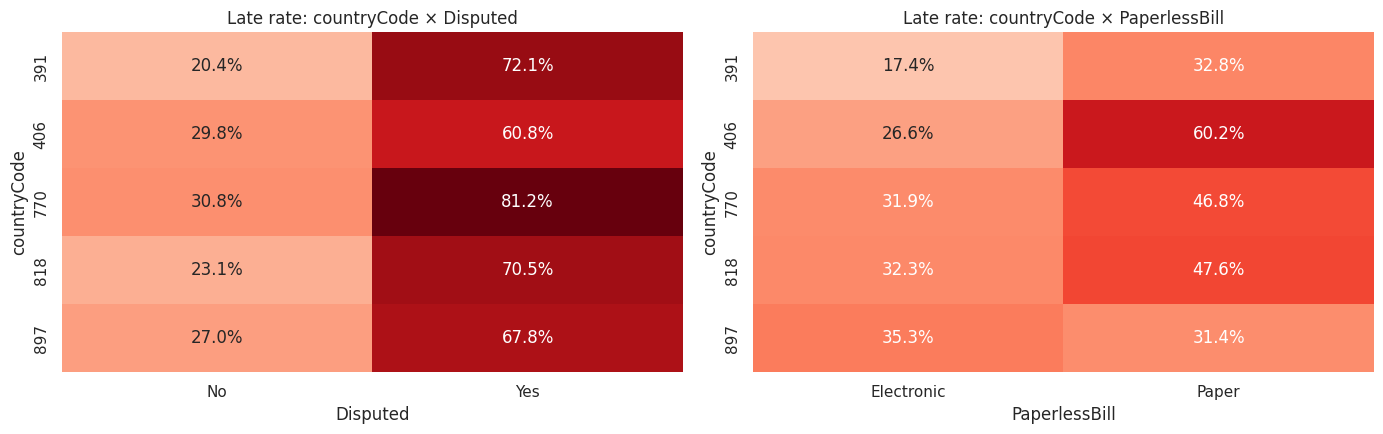

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ["Disputed", "PaperlessBill"]):
    pv = df.pivot_table(index="countryCode", columns=col, values="late_payment", aggfunc="mean")
    sns.heatmap(pv, annot=True, fmt=".1%", cmap="Reds", ax=ax, vmin=0, vmax=0.8, cbar=False)
    ax.set_title(f"Late rate: countryCode × {col}")
plt.tight_layout(); save_fig("09_country_cross_heatmaps"); plt.show()

### Statistical associations: chi-square, Cramér’s V and Mann–Whitney U
**What we have:** category counts and invoice amounts split by payment outcome. **Question:** are there observed associations, and how large are they? Chi-square tests categorical association; Cramér’s V summarises its strength from 0 to 1. Mann–Whitney compares the amount distributions using ranks.

A p-value is the probability of a result at least this extreme under the null assumptions, not the probability that a feature is important. We use 0.05 as a conventional exploratory cutoff, not a proof. Repeated invoices per customer are dependent, some cells may be sparse, and several tests are run. Treat p-values as descriptive exploration, not confirmed independent-invoice inference or a causal claim.

In [19]:
rows = []
for col in ["countryCode", "Disputed", "PaperlessBill", "inv_dow", "inv_month", "customerID"]:
    ct = pd.crosstab(df[col], df["late_payment"])
    chi2, pval, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append({"feature": col, "test": "chi-square", "p_value": pval, "effect_size (Cramér's V)": round(v, 3)})

u, pval = stats.mannwhitneyu(df.loc[df.late_payment == 1, "InvoiceAmount"],
                             df.loc[df.late_payment == 0, "InvoiceAmount"])
rows.append({"feature": "InvoiceAmount", "test": "Mann-Whitney U", "p_value": pval, "effect_size (Cramér's V)": np.nan})

tests = pd.DataFrame(rows)
tests["significant (p<0.05)"] = tests["p_value"] < 0.05
tests["p_value"] = tests["p_value"].apply(lambda x: f"{x:.2e}")
tests

Out[19]: 
         feature            test    p_value  effect_size (Cramér's V)  \
0    countryCode      chi-square   4.08e-09                     0.135   
1       Disputed      chi-square   2.64e-75                     0.370   
2  PaperlessBill      chi-square   5.19e-16                     0.163   
3        inv_dow      chi-square   3.67e-01                     0.051   
4      inv_month      chi-square   2.43e-01                     0.075   
5     customerID      chi-square  8.19e-179                     0.683   
6  InvoiceAmount  Mann-Whitney U   1.34e-02                       NaN   

   significant (p<0.05)  
0                  True  
1                  True  
2                  True  
3                 False  
4                 False  
5                  True  
6                  True  


**How to interpret the table:** A larger Cramér’s V indicates a stronger observed category/outcome association. Values near zero indicate weak association; they are not regression coefficients. A small p-value can occur for a weak association, so inspect the effect size too. These tests do not select the final model using test-set performance. Disputed remains excluded from the main pipeline because issue-time availability is uncertain.

## 3. Feature engineering and correlation
We preserve the original binary-mapping and customer-history exploration. Fixed mappings such as Yes → 1 and No → 0 do not learn from the target. The production comparisons below fit one-hot encoders inside training folds; we do not reuse full-data dummy matrices for cross-validation.

In [20]:
df['Disputed_bin'] = df['Disputed'].map({'Yes':1, 'No':0})
df['Paperless_bin'] = df['PaperlessBill'].map({'Electronic':1, 'Paper':0})
print('Fixed binary mapping used for EDA only.')
print('Nominal categories will use a fold-fitted OneHotEncoder later.')

Fixed binary mapping used for EDA only.
Nominal categories will use a fold-fitted OneHotEncoder later.


### 5.2 A data quirk: `PaperlessDate`
Let's see how `PaperlessDate` relates to `InvoiceDate`.

In [21]:
df["days_since_paperless"] = (df["InvoiceDate"] - df["PaperlessDate"]).dt.days
print(df.groupby("PaperlessBill")["days_since_paperless"].describe().round(0))

                count   mean    std    min    25%    50%    75%    max
PaperlessBill                                                         
Electronic     1203.0  221.0  153.0    1.0   96.0  199.0  322.0  676.0
Paper          1263.0 -220.0  155.0 -694.0 -322.0 -197.0  -94.0    0.0


**Output and interpretation:** PaperlessDate has a strong relationship with billing type in this sample: it is generally before issue for electronic bills and after issue for paper bills. This raises availability/redundancy concerns. We exclude it rather than assume its future-dated values would be known at prediction time. The pattern does not prove that every possible date-derived feature contains no additional information.

### Customer-history features: what was known at issue time?
For each invoice, use only records settled strictly before its invoice date. We calculate previous invoice count, late rate, mean delay and last-five late rate. First invoices have no history, so rates are missing rather than falsely set to zero.

These are an exploratory **rolling-ledger** feature set: in a later validation period, earlier payments already settled during that period can become available for later predictions. This assumes a real ledger can be updated. Random shuffled CV is inappropriate for this feature set because held-out outcomes can enter later training histories. We use chronological folds for history experiments and keep the simple ID-based main pipeline separate.

In [22]:
def add_customer_history(data):
    # For each invoice, summarise only the customer's invoices that were already PAID before it was issued.
    out = {k: {} for k in ["prev_invoices", "prev_late_rate", "prev_avg_days_late", "prev_last5_late_rate"]}
    for cust_id, grp in data.groupby("customerID"):
        settled = grp["SettledDate"].values
        late    = grp["late_payment"].values
        dlate   = grp["DaysLate"].values
        for idx, inv_date in zip(grp.index, grp["InvoiceDate"].values):
            mask = settled < inv_date                        # already paid at the time of this invoice
            n = int(mask.sum())
            out["prev_invoices"][idx] = n
            if n > 0:
                order = np.argsort(settled[mask])            # oldest -> newest payment
                out["prev_late_rate"][idx]       = late[mask].mean()
                out["prev_avg_days_late"][idx]   = dlate[mask].mean()
                out["prev_last5_late_rate"][idx] = late[mask][order][-5:].mean()
            else:
                out["prev_late_rate"][idx] = out["prev_avg_days_late"][idx] = out["prev_last5_late_rate"][idx] = np.nan
    return pd.DataFrame(out).reindex(data.index)

hist = add_customer_history(df)
df = pd.concat([df.drop(columns=[c for c in hist.columns if c in df.columns]), hist], axis=1)
df["has_history"] = (df["prev_invoices"] > 0).astype(int)

print(f"Invoices with no payment history yet: {(df['has_history'] == 0).sum()} ({(df['has_history'] == 0).mean():.1%})")
df[["customerID", "InvoiceDate", "prev_invoices", "prev_late_rate", "prev_avg_days_late", "prev_last5_late_rate", "late_payment"]].sort_values(["customerID", "InvoiceDate"]).head(8)

Invoices with no payment history yet: 194 (7.9%)
Out[22]: 
      customerID InvoiceDate  prev_invoices  prev_late_rate  \
991   0187-ERLSR  2012-03-29              0             NaN   
2345  0187-ERLSR  2012-05-15              1             0.0   
2401  0187-ERLSR  2012-05-21              1             0.0   
1791  0187-ERLSR  2012-06-16              3             0.0   
445   0187-ERLSR  2012-09-05              4             0.0   
1001  0187-ERLSR  2012-09-22              5             0.0   
1220  0187-ERLSR  2012-12-06              6             0.0   
1030  0187-ERLSR  2013-02-16              7             0.0   

      prev_avg_days_late  prev_last5_late_rate  late_payment  
991                  NaN                   NaN             0  
2345                 0.0                   0.0             0  
2401                 0.0                   0.0             0  
1791                 0.0                   0.0             0  
445                  0.0                   0.0            

Rows with no history have `NaN` (missing) in the `prev_*` columns — correct, there is nothing to summarise. The modelling pipelines fill these with the median (the `SimpleImputer` step), and `has_history` lets models know the value was missing.

### Two feature representations retained from the original notebook
A uses customer identity; B uses previous-payment history and issue-time month/weekday. Their corrected comparison below uses raw inputs with fold-fitted preprocessing. Disputed is excluded from both main comparisons and tested separately as an explicitly unavailable-at-issue sensitivity experiment.

In [23]:
hist_cols = ['prev_invoices','prev_late_rate','prev_avg_days_late','prev_last5_late_rate','has_history']
print('A: customerID, countryCode, PaperlessBill, InvoiceAmount')
print('B: countryCode, PaperlessBill, InvoiceAmount, month, weekday and five history fields')
print('History features with missing values:')
display(df[hist_cols].isna().sum().to_frame('missing'))

A: customerID, countryCode, PaperlessBill, InvoiceAmount
B: countryCode, PaperlessBill, InvoiceAmount, month, weekday and five history fields
History features with missing values:


,missing
prev_invoices,0
prev_late_rate,194
prev_avg_days_late,194
prev_last5_late_rate,194
has_history,0


### 5.5 Correlation heatmap
**Correlation** (−1 … +1) shows how strongly two numeric columns move together. +1 = rise together, −1 = one rises as the other falls, 0 = unrelated.
We include `DaysLate` and `DaysToSettle` *on purpose*: their huge correlation with the target is exactly the leakage we must avoid.

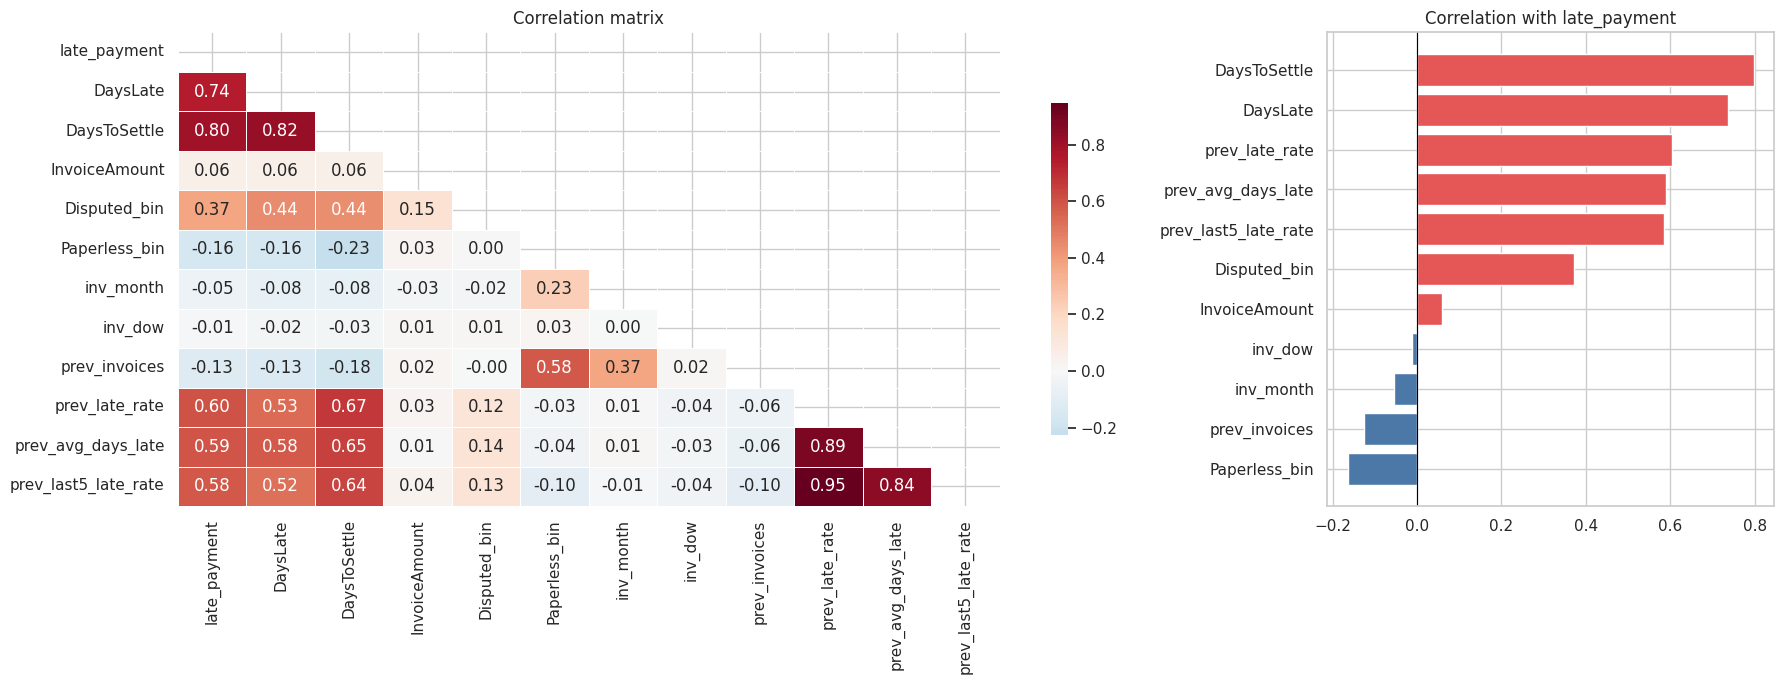

In [24]:
corr_cols = ["late_payment", "DaysLate", "DaysToSettle", "InvoiceAmount", "Disputed_bin", "Paperless_bin",
             "inv_month", "inv_dow", "prev_invoices", "prev_late_rate", "prev_avg_days_late", "prev_last5_late_rate"]
corr = df[corr_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [2.3, 1]})
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5,
            cbar_kws={"shrink": 0.7}, ax=axes[0])
axes[0].set_title("Correlation matrix")

tgt = corr["late_payment"].drop("late_payment").sort_values()
axes[1].barh(tgt.index, tgt.values, color=["#E45756" if v > 0 else "#4C78A8" for v in tgt.values])
axes[1].set_title("Correlation with late_payment"); axes[1].axvline(0, color="black", lw=0.8)
plt.tight_layout(); save_fig("10_correlation"); plt.show()

**Interpretation:** Pearson correlation ranges from −1 to +1 and describes linear association. Near zero does not rule out a nonlinear relationship. Delay/settlement fields correlate with the target because they contain outcome information and must not be inputs. Correlations with binary mappings describe those particular encodings. Correlation is not causation.

**Scope of EDA:** These full-dataset charts reproduce the original descriptive exploration. The same test period was already inspected in the earlier project, so this revised evaluation is not a completely new blind test. New preprocessing fits and hyperparameter choices below are restricted to training/validation data.

## 4. Chronological split and outcome availability

**What we have:** Invoice dates and settlement outcomes.

**What we need to know:** How do we simulate predicting later invoices from earlier records?

**Steps and why:** Sort by invoice date. Use the invoice dates at the 60% and 80% positions as boundaries; keep all same-date invoices together. Training labels must be known before validation begins, and validation labels before testing begins.

**How to read the output:** The initial fractions set boundaries, not exact final row percentages. Outcome filtering changes counts. 60/20/20 is a practical choice, not an optimised ratio. More training data leaves less validation evidence; larger test sets give more evaluation data but less data for learning. We do not choose a split because it gives the highest test score.

In [25]:
data = df.copy().sort_values('InvoiceDate', kind='stable').reset_index(drop=True)
data['days_overdue'] = (data.SettledDate - data.DueDate).dt.days.clip(lower=0)
data['is_late'] = (data.days_overdue > 0).astype(int)
assert data[['InvoiceDate','DueDate','SettledDate']].notna().all().all()
assert (data.DueDate >= data.InvoiceDate).all()
assert (data.SettledDate >= data.InvoiceDate).all()
assert (data.InvoiceAmount > 0).all()
for c in ['customerID','countryCode','PaperlessBill']: data[c] = data[c].astype(str)
def split_at_fractions(frame, train_fraction=.6, validation_fraction=.2):
    v = frame.InvoiceDate.iloc[int(len(frame)*train_fraction)]
    t = frame.InvoiceDate.iloc[int(len(frame)*(train_fraction+validation_fraction))]
    a = frame[(frame.InvoiceDate < v) & (frame.SettledDate < v)].copy().reset_index(drop=True)
    b = frame[(frame.InvoiceDate >= v)&(frame.InvoiceDate < t)&(frame.SettledDate < t)].copy().reset_index(drop=True)
    c = frame[frame.InvoiceDate >= t].copy().reset_index(drop=True)
    return a,b,c,v,t
train, validation, test, validation_start, test_start = split_at_fractions(data)
rows=[]
for label, part in [('Train',train),('Validation',validation),('Test',test)]:
    rows.append({'split':label,'rows':len(part),'late_percent':100*part.is_late.mean(),'start':part.InvoiceDate.min().date(),'end':part.InvoiceDate.max().date()})
display(pd.DataFrame(rows))
print('Excluded:',len(data)-len(train)-len(validation)-len(test))
print('Validation starts:',validation_start.date(),'Test starts:',test_start.date())
y_train,y_val,y_test=[p.is_late for p in [train,validation,test]]
r_train,r_val,r_test=[p.days_overdue for p in [train,validation,test]]
explain('Outcome filtering prevents future labels entering earlier training, but also excludes some outstanding invoices. This selection bias limits generalisation. A real deployment should handle outstanding/censored outcomes explicitly. The split was not used to balance classes.')
# Show how row allocations change, without fitting models on alternate outer splits.
allocation=[]
for a,b in [(.5,.25),(.6,.2),(.7,.15)]:
    tr,va,te,v,t=split_at_fractions(data,a,b)
    allocation.append({'planned_ratio':f'{a:.0%}/{b:.0%}/{1-a-b:.0%}','train':len(tr),'validation':len(va),'test':len(te),'excluded':len(data)-len(tr)-len(va)-len(te)})
display(pd.DataFrame(allocation))

Excluded: 167
Validation starts: 2013-02-26 Test starts: 2013-07-12


,split,rows,late_percent,start,end
0,Train,1390,37.410072,2012-01-03,2013-02-14
1,Validation,409,31.784841,2013-02-26,2013-07-03
2,Test,500,28.400000,2013-07-12,2013-12-02


**Output and conclusion:** Outcome filtering prevents future labels entering earlier training, but also excludes some outstanding invoices. This selection bias limits generalisation. A real deployment should handle outstanding/censored outcomes explicitly. The split was not used to balance classes.

,planned_ratio,train,validation,test,excluded
0,50%/25%/25%,1138,511,621,196
1,60%/20%/20%,1390,409,500,167
2,70%/15%/15%,1623,290,371,182


## 5. Preprocessing and an explicit feature-selection method

**What we have:** Three categorical inputs, amount and derived payment terms.

**What we need to know:** How are raw invoices converted into model-ready values without leakage?

**Steps and why:** For numerical fields: median imputation → standard scaling. For categories: most-frequent imputation → one-hot encoding. Then VarianceThreshold(0.0) removes constant columns. All steps are fitted only inside training folds.

**How to read the output:** Zero is chosen because we remove only features with no variation, not rare customer categories. Payment terms are included so the selector demonstrably removes the constant 30-day field. This is a simple unsupervised filter, not proof that all retained features are useful. The raw candidates are five; encoded counts are printed rather than confused with raw counts.

For a constant column such as payment terms, StandardScaler uses a scale factor of 1 rather than dividing by zero. It becomes zero after centring, and VarianceThreshold removes it.

In [26]:
categorical_features=['customerID','countryCode','PaperlessBill']
numeric_features=['InvoiceAmount','payment_terms_days']
features=categorical_features+numeric_features
X_train,X_val,X_test=[p[features] for p in [train,validation,test]]
def preprocessor_for(cats, nums):
    return ColumnTransformer([
        ('categories',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
            ('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cats),
        ('numbers',Pipeline([('impute',SimpleImputer(strategy='median')),
            ('scale',StandardScaler())]),nums)])
def make_pipeline(model,cats=None,nums=None):
    return Pipeline([('preprocess',preprocessor_for(categorical_features if cats is None else cats,numeric_features if nums is None else nums)),
                     ('select',VarianceThreshold(threshold=0.0)),('model',clone(model))])
selection_demo=make_pipeline(LogisticRegression(max_iter=3000)).fit(X_train,y_train)
encoded=selection_demo.named_steps['preprocess'].get_feature_names_out()
support=selection_demo.named_steps['select'].get_support()
display(pd.DataFrame({'encoded_feature':encoded,'variance':selection_demo.named_steps['select'].variances_,'retained':support}))
print('Raw candidates:',len(features),'Encoded before selection:',len(encoded),'After selection:',support.sum())
print('Removed:',encoded[~support].tolist())
scaler=selection_demo.named_steps['preprocess'].named_transformers_['numbers'].named_steps['scale']
display(pd.DataFrame({'feature':numeric_features,'training_mean':scaler.mean_,'training_std':np.sqrt(scaler.var_)}))
explain('StandardScaler uses z=(x−training mean)/training standard deviation. It does not cap values or make every distribution normal. Unknown categories map to zeros with handle_unknown=ignore; that prevents an error but does not establish new-customer accuracy. The app should still flag unsupported customers. No original missing values needed filling; imputers also support CV history experiments and defensive future inputs.')

Raw candidates: 5 Encoded before selection: 109 After selection: 108
Removed: ['numbers__payment_terms_days']


,encoded_feature,variance,retained
0,categories__customerID_0187-ERLSR,0.005011,True
1,categories__customerID_0379-NEVHP,0.009265,True
2,categories__customerID_0465-DTULQ,0.012782,True
3,categories__customerID_0625-TNJFG,0.010675,True
4,categories__customerID_0688-XNJRO,0.012081,True
...,...,...,...
104,categories__countryCode_897,0.136639,True
105,categories__PaperlessBill_Electronic,0.196336,True
106,categories__PaperlessBill_Paper,0.196336,True
107,numbers__InvoiceAmount,1.000000,True


,feature,training_mean,training_std
0,InvoiceAmount,59.514496,20.415289
1,payment_terms_days,30.000000,0.000000


**Output and conclusion:** StandardScaler uses z=(x−training mean)/training standard deviation. It does not cap values or make every distribution normal. Unknown categories map to zeros with handle_unknown=ignore; that prevents an error but does not establish new-customer accuracy. The app should still flag unsupported customers. No original missing values needed filling; imputers also support CV history experiments and defensive future inputs.

## 6. Cross-validation within the training period

**What we have:** The outer training partition; validation and test remain outside GridSearchCV.

**What we need to know:** Which hyperparameters work across earlier-to-later training windows?

**Steps and why:** Use three expanding calendar windows. At each fold, train only on labels settled before the fold evaluation starts; score only outcomes known before its end. Pass the index pairs directly to GridSearchCV.

**How to read the output:** Three folds balance runtime and evidence on this small dataset. Standard TimeSeriesSplit alone does not know settlement dates, so explicit date and availability masks are required. Fold durations are equal calendar windows; retained sample counts differ. CV standard deviation describes variation, not a confidence interval.

In [27]:
# Four equal calendar intervals: initial training window plus three forward evaluations.
calendar_edges = pd.date_range(train.InvoiceDate.min(), validation_start, periods=5)
cv_folds=[]; fold_rows=[]
for k in range(1,4):
    start,end=calendar_edges[k],calendar_edges[k+1]
    tr=np.flatnonzero(((train.InvoiceDate<start)&(train.SettledDate<start)).to_numpy())
    va=np.flatnonzero(((train.InvoiceDate>=start)&(train.InvoiceDate<end)&(train.SettledDate<end)).to_numpy())
    assert len(tr)>0 and len(va)>0
    assert train.iloc[tr].is_late.nunique()==2 and train.iloc[va].is_late.nunique()==2
    assert train.iloc[tr].SettledDate.max()<start
    cv_folds.append((tr,va))
    fold_rows.append({'fold':k,'train_rows':len(tr),'evaluation_rows':len(va),'evaluation_start':start,'evaluation_end':end,'train_late_share':train.iloc[tr].is_late.mean()})
display(pd.DataFrame(fold_rows))

,fold,train_rows,evaluation_rows,evaluation_start,evaluation_end,train_late_share
0,1,253,259,2012-04-17,2012-07-31,0.367589
1,2,620,281,2012-07-31,2012-11-13,0.383871
2,3,998,295,2012-11-13,2013-02-26,0.388778


## 7. Models and metrics: what is being compared?
| Classifier | How it works | Useful when / limitation |
|---|---|---|
| Logistic Regression | Adds weighted features and passes the score through a sigmoid | Simple additive effects; cannot automatically learn arbitrary interactions |
| Decision Tree | Learns if/else splits | Easy nonlinear rules; a deep tree can memorise records |
| Random Forest | Averages many independently varied trees | Nonlinear interactions and robust averaging; harder to explain |
| Gradient Boosting | Adds trees to improve the current fit | Complex patterns; learning rate/depth need control |
| XGBoost | Regularised gradient-boosted trees | Flexible boosting; extra complexity is not automatically better |
| Dummy baseline | Predicts the training class frequency | Checks whether real models add information |

**Classification measures:** precision = TP/(TP+FP); recall = TP/(TP+FN); F1 = 2PR/(P+R); accuracy = (TP+TN)/N. ROC-AUC measures ranking across thresholds: 0.5 is random ranking, 1 is perfect ranking. Average precision (AP) summarises precision–recall performance and is not accuracy; a constant-score baseline's AP equals the late prevalence in the evaluation set. Changing the threshold changes precision/recall/F1, not AP or ROC-AUC.

**Regression:** Ridge predicts a weighted sum with an L2 penalty; Random Forest averages tree predictions; Gradient Boosting adds trees to reduce residual errors. MAE is mean absolute error in days. RMSE is the square root of mean squared error and penalises large mistakes. R²=1−SSE/SST compares with the evaluation set's mean: 1 is perfect, 0 matches that mean, and negative is worse. Late-only MAE evaluates actually late invoices; it is not a separate model trained only on late rows.

No model is universally best. We choose classifier hyperparameters by training-CV AP, the classifier family by validation AP, and per-model thresholds by validation F1. Regressors use clipped-prediction MAE for CV and validation. Ties are not evidence of meaningful superiority.

In [28]:
def classification_metrics(y,p,t=.5):
    z=np.asarray(p)>=t
    return {'AP':average_precision_score(y,p),'ROC_AUC':roc_auc_score(y,p),
            'Precision':precision_score(y,z,zero_division=0),'Recall':recall_score(y,z,zero_division=0),
            'F1':f1_score(y,z,zero_division=0),'Accuracy':accuracy_score(y,z)}
def regression_metrics(y,p):
    y=np.asarray(y);p=np.maximum(0,np.asarray(p));late=y>0
    return {'MAE':mean_absolute_error(y,p),'RMSE':np.sqrt(mean_squared_error(y,p)),
            'R2':r2_score(y,p),'Late_only_MAE':mean_absolute_error(y[late],p[late]) if late.any() else np.nan}
def clipped_mae(y,p): return mean_absolute_error(y,np.maximum(0,p))
reg_scorer=make_scorer(clipped_mae,greater_is_better=False)
classification_scoring={'AP':'average_precision','ROC_AUC':'roc_auc',
    'Precision':make_scorer(precision_score,zero_division=0),
    'Recall':make_scorer(recall_score,zero_division=0),
    'F1':make_scorer(f1_score,zero_division=0),'Accuracy':'accuracy'}
classification_candidates={
 'Logistic Regression':LogisticRegression(max_iter=3000,random_state=SEED),
 'Decision Tree':DecisionTreeClassifier(max_depth=5,min_samples_leaf=10,random_state=SEED),
 'Random Forest':RandomForestClassifier(n_estimators=150,min_samples_leaf=4,n_jobs=1,random_state=SEED),
 'Gradient Boosting':GradientBoostingClassifier(n_estimators=100,learning_rate=.05,max_depth=2,random_state=SEED),
 'XGBoost':XGBClassifier(n_estimators=100,learning_rate=.05,max_depth=3,subsample=.8,colsample_bytree=.8,eval_metric='logloss',n_jobs=1,random_state=SEED)}
regression_candidates={
 'Ridge':Ridge(alpha=1),
 'Random Forest Regressor':RandomForestRegressor(n_estimators=150,min_samples_leaf=4,n_jobs=1,random_state=SEED),
 'Gradient Boosting Regressor':GradientBoostingRegressor(n_estimators=100,learning_rate=.05,max_depth=2,random_state=SEED)}

## 8. Original A/B feature comparison, corrected

**What we have:** Customer-ID features (A) and rolling-history features (B).

**What we need to know:** Does more feature engineering improve chronological validation performance?

**Steps and why:** Fit the five classifier families on both feature sets using the same outcome-aware training folds. Fit imputers/encoders/scalers inside each fold. Remove Disputed from this main comparison.

**How to read the output:** These are untuned comparative experiments; the later deployment-track grid search uses A for consistency with the existing app. B assumes a live ledger, and is not interchangeable with the app’s four extracted fields. Its median-filled first-customer rates are estimates, not actual historical observations.

,feature_set,Model,AP,AP_std,ROC_AUC,ROC_AUC_std,Precision,Precision_std,Recall,Recall_std,F1,F1_std,Accuracy,Accuracy_std,Train_ROC_AUC
0,A: Customer identity,Dummy baseline,0.3218,0.0190,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.6782,0.0190,0.5000
1,A: Customer identity,Logistic Regression,0.7280,0.0247,0.8383,0.0284,0.7858,0.0159,0.5227,0.0385,0.6272,0.0308,0.8001,0.0227,0.9400
2,A: Customer identity,Decision Tree,0.3817,0.0416,0.5973,0.0459,0.4797,0.1339,0.1549,0.0708,0.2150,0.0846,0.6546,0.0536,0.6720
3,A: Customer identity,Random Forest,0.6143,0.1307,0.7686,0.0913,0.5216,0.3691,0.2345,0.1836,0.3174,0.2359,0.7301,0.0541,0.8617
4,A: Customer identity,Gradient Boosting,0.6067,0.0434,0.7211,0.0576,0.8139,0.1103,0.2870,0.0247,0.4209,0.0225,0.7461,0.0233,0.8162
5,A: Customer identity,XGBoost,0.5501,0.1331,0.6918,0.1076,0.7271,0.1987,0.2272,0.0225,0.3382,0.0320,0.7113,0.0475,0.8456
6,B: Rolling history,Dummy baseline,0.3218,0.0190,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.6782,0.0190,0.5000
7,B: Rolling history,Logistic Regression,0.7629,0.0179,0.8482,0.0229,0.8263,0.0545,0.4363,0.0895,0.5618,0.0677,0.7856,0.0253,0.7987
8,B: Rolling history,Decision Tree,0.6736,0.0794,0.7871,0.0499,0.7578,0.0331,0.6159,0.0116,0.6794,0.0194,0.8120,0.0237,0.8224
9,B: Rolling history,Random Forest,0.7469,0.0105,0.8305,0.0238,0.9038,0.0698,0.2870,0.2019,0.3863,0.2408,0.7524,0.0632,0.9184


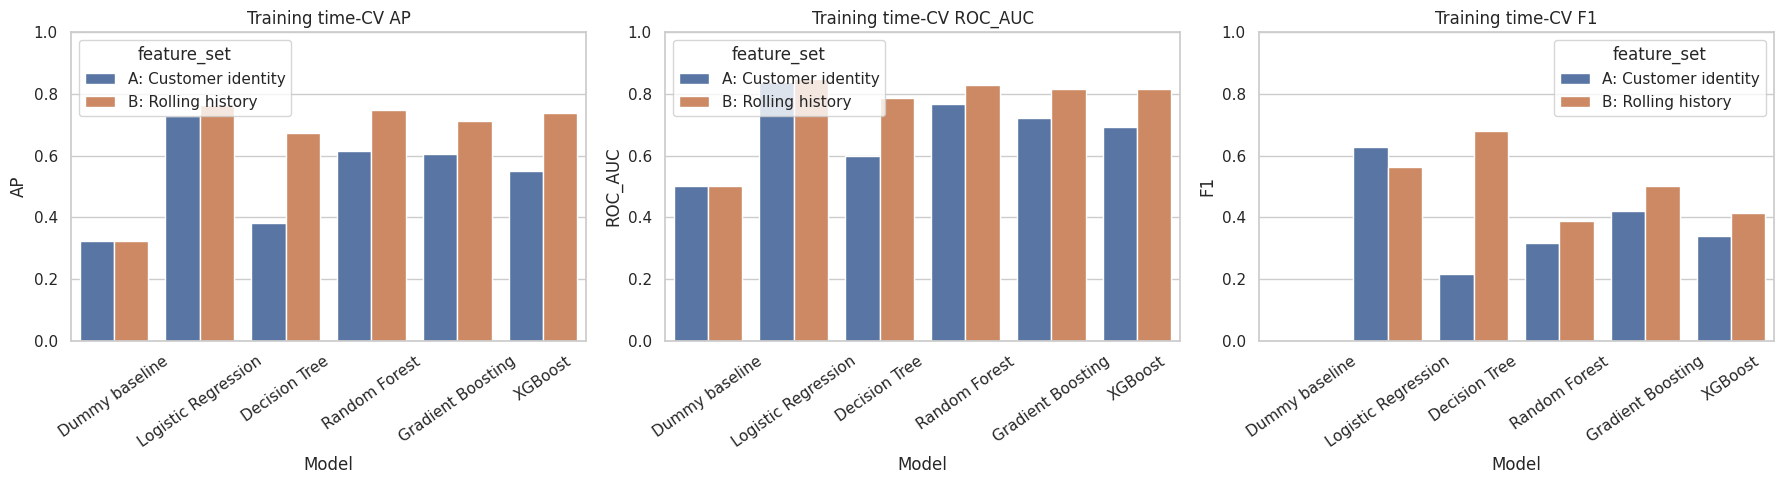

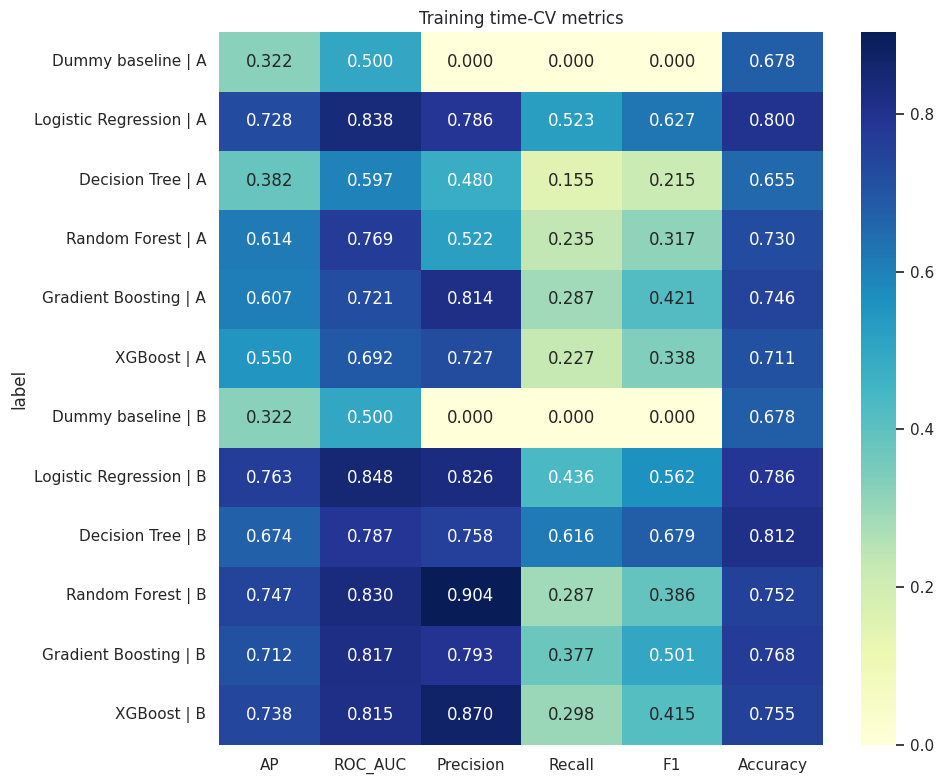

**Output and conclusion:** The highest untuned time-CV AP is 0.7629 for Logistic Regression on B: Rolling history. This does not choose the final app model. It tests the original feature-engineering question under chronological evaluation.

In [29]:
history_cats=['countryCode','PaperlessBill']
history_nums=['InvoiceAmount','inv_month','inv_dow']+hist_cols
feature_specs={'A: Customer identity':(categorical_features,numeric_features),
               'B: Rolling history':(history_cats,history_nums)}
comparison_rows=[]
for set_name,(cats,nums) in feature_specs.items():
    for name,model in {'Dummy baseline':DummyClassifier(strategy='prior'),**classification_candidates}.items():
        result=cross_validate(make_pipeline(model,cats,nums),train[cats+nums],y_train,
            cv=cv_folds,scoring=classification_scoring,return_train_score=True,n_jobs=N_JOBS)
        row={'feature_set':set_name,'Model':name}
        for metric in classification_scoring:
            row[metric]=result['test_'+metric].mean();row[metric+'_std']=result['test_'+metric].std()
        row['Train_ROC_AUC']=result['train_ROC_AUC'].mean()
        comparison_rows.append(row)
feature_comparison=pd.DataFrame(comparison_rows)
display(feature_comparison.round(4))
fig,axes=plt.subplots(1,3,figsize=(18,5))
for ax,m in zip(axes,['AP','ROC_AUC','F1']):
    sns.barplot(data=feature_comparison,x='Model',y=m,hue='feature_set',ax=ax,errorbar=None)
    ax.tick_params(axis='x',rotation=35);ax.set_title('Training time-CV '+m);ax.set_ylim(0,1)
plt.tight_layout();save_fig('11_feature_model_comparison');plt.show()
heat=feature_comparison.assign(label=lambda x:x.Model+' | '+x.feature_set.str[0]).set_index('label')[list(classification_scoring)]
plt.figure(figsize=(10,8));sns.heatmap(heat,annot=True,fmt='.3f',cmap='YlGnBu');plt.title('Training time-CV metrics');plt.tight_layout();plt.show()
lead=feature_comparison.sort_values('AP',ascending=False).iloc[0]
explain(f"The highest untuned time-CV AP is {lead.AP:.4f} for {lead.Model} on {lead.feature_set}. This does not choose the final app model. It tests the original feature-engineering question under chronological evaluation.")

## 9. Class imbalance: ordinary, weighted and SMOTE

**What we have:** Training contains more on-time than late invoices.

**What we need to know:** Does reweighting or synthetic oversampling help?

**Steps and why:** Run the original Random Forest imbalance comparison on the same folds. Balanced class weights are computed within each estimator fit. SMOTE is applied only to the training portion of a fold, never to validation/test.

**How to read the output:** Class weights change the loss, not the row count. SMOTE creates interpolated minority samples. On one-hot customer categories it can create fractional indicator values, so this experiment is retained for comparison, not adopted as a valid new customer generator. Imbalance does not itself prove overfitting.

,training_count,balanced_weight
class,,
0,870,0.798851
1,520,1.336538


,Strategy,AP,ROC_AUC,Precision,Recall,F1,Accuracy
0,Ordinary,0.6143,0.7686,0.5216,0.2345,0.3174,0.7301
1,Class weights,0.6005,0.7621,0.5940,0.5844,0.5888,0.7325
2,SMOTE (exploratory),0.6516,0.7766,0.6943,0.4841,0.5689,0.7660


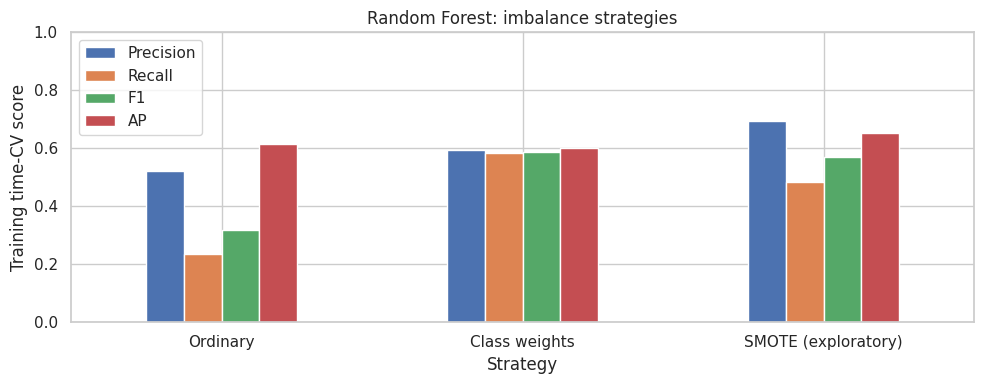

**Output and conclusion:** Compare both recall and precision. A recall gain may come with more false alerts. No automatic conclusion that equal class influence is better is justified.

In [30]:
counts=y_train.value_counts().sort_index()
weights=len(y_train)/(2*counts)
display(pd.DataFrame({'training_count':counts,'balanced_weight':weights}).rename_axis('class'))
rf=classification_candidates['Random Forest']
ordinary=make_pipeline(rf)
weighted=make_pipeline(clone(rf).set_params(class_weight='balanced'))
smote=ImbPipeline([('preprocess',preprocessor_for(categorical_features,numeric_features)),
 ('select',VarianceThreshold(0)),('smote',SMOTE(random_state=SEED,k_neighbors=3)),('model',clone(rf))])
imbalance_rows=[]
for name,pipeline in {'Ordinary':ordinary,'Class weights':weighted,'SMOTE (exploratory)':smote}.items():
    scores=cross_validate(pipeline,X_train,y_train,cv=cv_folds,scoring=classification_scoring,n_jobs=N_JOBS)
    imbalance_rows.append({'Strategy':name,**{m:scores['test_'+m].mean() for m in classification_scoring}})
imbalance_comparison=pd.DataFrame(imbalance_rows);display(imbalance_comparison.round(4))
imbalance_comparison.set_index('Strategy')[['Precision','Recall','F1','AP']].plot.bar(figsize=(10,4),rot=0)
plt.ylabel('Training time-CV score');plt.ylim(0,1);plt.title('Random Forest: imbalance strategies');plt.tight_layout();plt.show()
explain('Compare both recall and precision. A recall gain may come with more false alerts. No automatic conclusion that equal class influence is better is justified.')

## 10. Hyperparameter tuning using GridSearchCV

**What we have:** Five classifier families and three regressors with fixed initial settings.

**What we need to know:** Which settings work best within the training period?

**Steps and why:** GridSearchCV tries every specified combination over the same three time folds, fits preprocessing anew, and refits the chosen setting on the full training partition. Classification uses AP; regression uses negative clipped MAE so larger search scores mean smaller errors.

**How to read the output:** A hyperparameter is chosen before fitting, e.g. tree depth or regularisation strength. A coefficient is learned during fitting. best_params_ prints actual selected settings; it is not chosen from the test set. Small grids are deliberate for a small dataset and CPU runtime, not exhaustive optimisation.

### Why these parameter values?
- Logistic Regression `C=[0.1,1,10]`: tests stronger, default-scale and weaker regularisation. Smaller C means stronger regularisation. `class_weight=[None,'balanced']` checks imbalance handling inside each fold.
- Decision Tree `max_depth=[3,6]`, `min_samples_leaf=[4,10]`: compare simpler and more flexible rules; larger leaves resist memorisation.
- Random Forest `n_estimators=[100,200]`, `max_depth=[6,None]`, `min_samples_leaf=[2,4]`: compare averaging size and flexibility. Classifier also tests class weights. More trees usually stabilise averaging but cost time.
- Both boosting families use `learning_rate=[0.05,0.1]` and shallow depths `[2,3]`. Smaller steps learn more slowly. XGBoost also tests 100/200 trees; its 0.8 row/column sampling adds diversity. XGBoost weighting is tested separately below with fold-specific weights.
- Ridge `alpha=[0.1,1,10,100]`: larger alpha penalises coefficients more strongly.

These are reasonable search ranges, not universally optimal values. `random_state=42` fixes randomness; `n_jobs=2` limits parallel resource use; `max_iter=3000` is a convergence allowance for Logistic Regression, not its chosen model complexity.

In [31]:
classification_grids={
 'Logistic Regression':{'model__C':[.1,1,10],'model__class_weight':[None,'balanced']},
 'Decision Tree':{'model__max_depth':[3,6],'model__min_samples_leaf':[4,10]},
 'Random Forest':{'model__n_estimators':[100,200],'model__max_depth':[6,None],
                  'model__min_samples_leaf':[2,4],'model__class_weight':[None,'balanced']},
 'Gradient Boosting':{'model__learning_rate':[.05,.1],'model__max_depth':[2,3]},
 'XGBoost':{'model__n_estimators':[100,200],'model__learning_rate':[.05,.1],'model__max_depth':[2,3]}}
regression_grids={
 'Ridge':{'model__alpha':[.1,1,10,100]},
 'Random Forest Regressor':{'model__n_estimators':[100,200],'model__max_depth':[6,None],'model__min_samples_leaf':[2,4]},
 'Gradient Boosting Regressor':{'model__n_estimators':[100,200],'model__learning_rate':[.05,.1],'model__max_depth':[2,3]}}
print('Classifier parameter combinations:',sum(len(ParameterGrid(g)) for g in classification_grids.values()))
print('Regression parameter combinations:',sum(len(ParameterGrid(g)) for g in regression_grids.values()))
classification_searches={};classification_models={};search_rows=[]
for name,model in classification_candidates.items():
    start=time.time()
    search=GridSearchCV(make_pipeline(model),classification_grids[name],cv=cv_folds,
        scoring=classification_scoring,refit='AP',return_train_score=True,n_jobs=N_JOBS,error_score='raise')
    search.fit(X_train,y_train)
    classification_searches[name]=search;classification_models[name]=search.best_estimator_
    search_rows.append({'Model':name,'Best_CV_AP':search.best_score_,
      'CV_AP_std':search.cv_results_['std_test_AP'][search.best_index_],
      'Mean_train_AP':search.cv_results_['mean_train_AP'][search.best_index_],
      'Parameters':search.best_params_,'Seconds':time.time()-start})
    print('Completed classifier:',name,flush=True)
    print('Chosen parameters:',json.dumps(search.best_params_,indent=2))
classification_search_summary=pd.DataFrame(search_rows);display(classification_search_summary)
for name,search in classification_searches.items():
    print(name,'— top search results')
    display(pd.DataFrame(search.cv_results_)[['params','mean_test_AP','std_test_AP','mean_test_Precision','mean_test_Recall','mean_test_F1','rank_test_AP']].sort_values('rank_test_AP').head(5))

Classifier parameter combinations: 38
Regression parameter combinations: 20
Completed classifier: Logistic Regression
Chosen parameters: {
  "model__C": 10,
  "model__class_weight": null
}
Completed classifier: Decision Tree
Chosen parameters: {
  "model__max_depth": 6,
  "model__min_samples_leaf": 4
}
Completed classifier: Random Forest
Chosen parameters: {
  "model__class_weight": null,
  "model__max_depth": null,
  "model__min_samples_leaf": 2,
  "model__n_estimators": 100
}
Completed classifier: Gradient Boosting
Chosen parameters: {
  "model__learning_rate": 0.1,
  "model__max_depth": 2
}
Completed classifier: XGBoost
Chosen parameters: {
  "model__learning_rate": 0.1,
  "model__max_depth": 3,
  "model__n_estimators": 200
}
Logistic Regression — top search results
Decision Tree — top search results
Random Forest — top search results
Gradient Boosting — top search results
XGBoost — top search results


,Model,Best_CV_AP,CV_AP_std,Mean_train_AP,Parameters,Seconds
0,Logistic Regression,0.744643,0.022290,0.928676,"{'model__C': 10, 'model__class_weight': None}",1.393202
1,Decision Tree,0.446837,0.034657,0.572077,"{'model__max_depth': 6, 'model__min_samples_le...",0.890378
2,Random Forest,0.703459,0.056132,0.952314,"{'model__class_weight': None, 'model__max_dept...",20.644300
3,Gradient Boosting,0.685774,0.046346,0.880703,"{'model__learning_rate': 0.1, 'model__max_dept...",2.646619
4,XGBoost,0.599281,0.156562,0.882848,"{'model__learning_rate': 0.1, 'model__max_dept...",2.639264


,params,mean_test_AP,std_test_AP,mean_test_Precision,mean_test_Recall,mean_test_F1,rank_test_AP
4,"{'model__C': 10, 'model__class_weight': None}",0.744643,0.022290,0.757407,0.589101,0.662437,1
5,"{'model__C': 10, 'model__class_weight': 'balan...",0.742254,0.025052,0.693329,0.708568,0.700736,2
2,"{'model__C': 1, 'model__class_weight': None}",0.727977,0.024680,0.785762,0.522703,0.627198,3
3,"{'model__C': 1, 'model__class_weight': 'balanc...",0.725038,0.025529,0.684235,0.697359,0.690353,4
1,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.586301,0.048314,0.559049,0.537173,0.545803,5


,params,mean_test_AP,std_test_AP,mean_test_Precision,mean_test_Recall,mean_test_F1,rank_test_AP
2,"{'model__max_depth': 6, 'model__min_samples_le...",0.446837,0.034657,0.774603,0.219654,0.304608,1
3,"{'model__max_depth': 6, 'model__min_samples_le...",0.402166,0.042607,0.534583,0.192671,0.269080,2
0,"{'model__max_depth': 3, 'model__min_samples_le...",0.375612,0.061368,0.727599,0.147999,0.191662,3
1,"{'model__max_depth': 3, 'model__min_samples_le...",0.363801,0.047706,0.533196,0.191530,0.245434,4


,params,mean_test_AP,std_test_AP,mean_test_Precision,mean_test_Recall,mean_test_F1,rank_test_AP
4,"{'model__class_weight': None, 'model__max_dept...",0.703459,0.056132,0.806458,0.433154,0.549426,1
5,"{'model__class_weight': None, 'model__max_dept...",0.699744,0.058899,0.784615,0.425491,0.540604,2
12,"{'model__class_weight': 'balanced', 'model__ma...",0.697342,0.049916,0.690279,0.615065,0.648611,3
13,"{'model__class_weight': 'balanced', 'model__ma...",0.694858,0.053547,0.684024,0.588245,0.632410,4
0,"{'model__class_weight': None, 'model__max_dept...",0.662106,0.070043,0.840188,0.115635,0.203014,5


,params,mean_test_AP,std_test_AP,mean_test_Precision,mean_test_Recall,mean_test_F1,rank_test_AP
2,"{'model__learning_rate': 0.1, 'model__max_dept...",0.685774,0.046346,0.789452,0.383794,0.516120,1
3,"{'model__learning_rate': 0.1, 'model__max_dept...",0.684125,0.065950,0.765979,0.466659,0.575596,2
1,"{'model__learning_rate': 0.05, 'model__max_dep...",0.663129,0.044946,0.804376,0.338388,0.474715,3
0,"{'model__learning_rate': 0.05, 'model__max_dep...",0.606675,0.043355,0.813921,0.287030,0.420911,4


,params,mean_test_AP,std_test_AP,mean_test_Precision,mean_test_Recall,mean_test_F1,rank_test_AP
7,"{'model__learning_rate': 0.1, 'model__max_dept...",0.599281,0.156562,0.635385,0.406497,0.492606,1
5,"{'model__learning_rate': 0.1, 'model__max_dept...",0.594647,0.152247,0.676806,0.331866,0.442297,2
3,"{'model__learning_rate': 0.05, 'model__max_dep...",0.582839,0.153681,0.680721,0.320942,0.430177,3
6,"{'model__learning_rate': 0.1, 'model__max_dept...",0.569589,0.142530,0.663714,0.309733,0.414717,4
1,"{'model__learning_rate': 0.05, 'model__max_dep...",0.566254,0.143377,0.693122,0.249857,0.364122,5


In [32]:
regression_searches={};regression_models={};reg_search_rows=[]
for name,model in regression_candidates.items():
    search=GridSearchCV(make_pipeline(model),regression_grids[name],cv=cv_folds,
        scoring={'MAE':reg_scorer},refit='MAE',return_train_score=True,n_jobs=N_JOBS,error_score='raise')
    search.fit(X_train,r_train)
    regression_searches[name]=search;regression_models[name]=search.best_estimator_
    reg_search_rows.append({'Model':name,'Best_CV_MAE_days':-search.best_score_,
        'CV_MAE_std':search.cv_results_['std_test_MAE'][search.best_index_],
        'Mean_train_MAE':-search.cv_results_['mean_train_MAE'][search.best_index_],
        'Parameters':search.best_params_})
    print('Completed regressor:',name,flush=True)
    print('Chosen parameters:',json.dumps(search.best_params_,indent=2))
regression_search_summary=pd.DataFrame(reg_search_rows);display(regression_search_summary)
classification_models['Dummy baseline']=make_pipeline(DummyClassifier(strategy='prior')).fit(X_train,y_train)
regression_models['Median baseline']=make_pipeline(DummyRegressor(strategy='median')).fit(X_train,r_train)
explain('The dictionaries hold every fitted model in memory for comparison. No files containing extracted models are written. The tables show parameters selected from training CV, not manually chosen after viewing the test results.')

Completed regressor: Ridge
Chosen parameters: {
  "model__alpha": 0.1
}
Completed regressor: Random Forest Regressor
Chosen parameters: {
  "model__max_depth": null,
  "model__min_samples_leaf": 2,
  "model__n_estimators": 100
}
Completed regressor: Gradient Boosting Regressor
Chosen parameters: {
  "model__learning_rate": 0.1,
  "model__max_depth": 3,
  "model__n_estimators": 200
}


,Model,Best_CV_MAE_days,CV_MAE_std,Mean_train_MAE,Parameters
0,Ridge,2.657094,0.226146,2.316438,{'model__alpha': 0.1}
1,Random Forest Regressor,3.024341,0.529623,2.138098,"{'model__max_depth': None, 'model__min_samples..."
2,Gradient Boosting Regressor,3.070130,0.192414,2.182677,"{'model__learning_rate': 0.1, 'model__max_dept..."


**Output and conclusion:** The dictionaries hold every fitted model in memory for comparison. No files containing extracted models are written. The tables show parameters selected from training CV, not manually chosen after viewing the test results.

## 11. Validation comparison and thresholds for every classifier

**What we have:** Tuned pipelines fitted on training data.

**What we need to know:** Which model family should be the default, and where should each alert threshold be?

**Steps and why:** Compare all tuned models on validation. Select the default classifier by AP and the regressor by MAE. For every real classifier, choose the threshold maximising validation F1.

**How to read the output:** Tuning every model threshold avoids giving just one classifier that advantage. Threshold 0.5 is a conventional starting point, not a required risk cutoff. A threshold is a decision rule, not a learned coefficient. Validation is used for selection, so its winning score can be optimistic.

Validation at threshold 0.5
Validation at model-specific thresholds
Regression validation


,Model,AP,ROC_AUC,Precision,Recall,F1,Accuracy
4,XGBoost,0.8006,0.8934,0.8630,0.4846,0.6207,0.8117
0,Logistic Regression,0.7959,0.8986,0.7963,0.6615,0.7227,0.8386
2,Random Forest,0.7740,0.8659,0.8043,0.5692,0.6667,0.8191
3,Gradient Boosting,0.7370,0.8600,0.8873,0.4846,0.6269,0.8166
1,Decision Tree,0.5760,0.7169,0.8333,0.3462,0.4891,0.7702
5,Dummy baseline,0.3178,0.5000,0.0000,0.0000,0.0000,0.6822


,Model,Threshold,AP,ROC_AUC,Precision,Recall,F1,Accuracy
4,XGBoost,0.2881,0.8006,0.8934,0.7047,0.8077,0.7527,0.8313
0,Logistic Regression,0.3704,0.7959,0.8986,0.7661,0.7308,0.7480,0.8435
2,Random Forest,0.2767,0.7740,0.8659,0.6748,0.8462,0.7509,0.8215
3,Gradient Boosting,0.3353,0.7370,0.8600,0.6838,0.7154,0.6992,0.8044
1,Decision Tree,0.3329,0.5760,0.7169,0.5374,0.6077,0.5704,0.7090
5,Dummy baseline,0.5000,0.3178,0.5000,0.0000,0.0000,0.0000,0.6822


,Model,MAE,RMSE,R2,Late_only_MAE
1,Random Forest Regressor,2.7255,5.1289,0.3437,5.9438
0,Ridge,2.7352,5.0604,0.3611,5.9914
2,Gradient Boosting Regressor,3.1219,5.3944,0.2740,6.2758
3,Median baseline,3.1271,7.0612,-0.2440,9.8385


**Output and conclusion:** The validation-selected classifier is **XGBoost**, with threshold **0.2881**. The selected regressor is **Random Forest Regressor**. These replace the earlier default choices only if the revised app is later updated. We do not assume the old winners must remain winners.

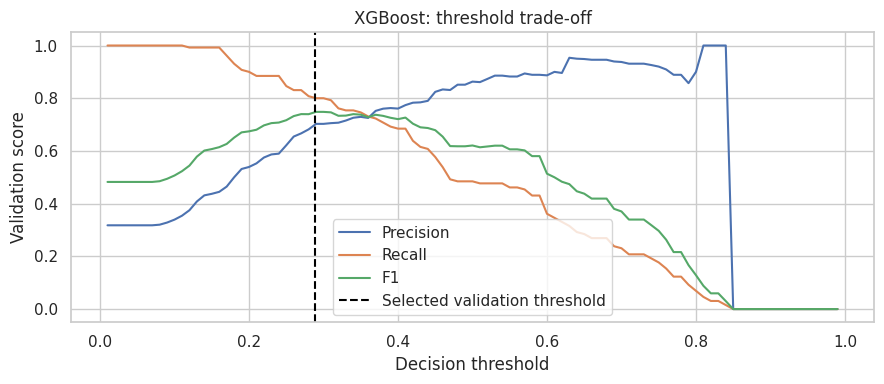

**Output and conclusion:** The classifier's validation AP lead over the runner-up is 0.0047; the regressor's validation MAE advantage is 0.0097 days. Small differences are not proof of statistically reliable superiority. CV and validation can favour different models because fold training sizes, customer coverage and calendar periods differ. Our selection rule was fixed before examining the test table.

In [33]:
thresholds_by_model={};val_default_rows=[];val_tuned_rows=[]
for name,model in classification_models.items():
    probability=model.predict_proba(X_val)[:,1]
    val_default_rows.append({'Model':name,**classification_metrics(y_val,probability)})
    precision,recall,thresholds=precision_recall_curve(y_val,probability)
    fs=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    threshold=.5 if name=='Dummy baseline' else float(thresholds[np.argmax(fs)])
    thresholds_by_model[name]=threshold
    val_tuned_rows.append({'Model':name,'Threshold':threshold,**classification_metrics(y_val,probability,threshold)})
classification_validation_default=pd.DataFrame(val_default_rows).sort_values('AP',ascending=False)
classification_validation=pd.DataFrame(val_tuned_rows).sort_values('AP',ascending=False)
regression_validation=pd.DataFrame([{'Model':n,**regression_metrics(r_val,m.predict(X_val))} for n,m in regression_models.items()]).sort_values('MAE')
print('Validation at threshold 0.5');display(classification_validation_default.round(4))
print('Validation at model-specific thresholds');display(classification_validation.round(4))
print('Regression validation');display(regression_validation.round(4))
best_classifier_name=classification_validation[classification_validation.Model!='Dummy baseline'].iloc[0].Model
best_regressor_name=regression_validation[regression_validation.Model!='Median baseline'].iloc[0].Model
best_classifier=classification_models[best_classifier_name];best_regressor=regression_models[best_regressor_name]
best_threshold=thresholds_by_model[best_classifier_name]
explain(f'The validation-selected classifier is **{best_classifier_name}**, with threshold **{best_threshold:.4f}**. The selected regressor is **{best_regressor_name}**. These replace the earlier default choices only if the revised app is later updated. We do not assume the old winners must remain winners.')
# Default classifier threshold trade-off, retained from the original analysis.
p=best_classifier.predict_proba(X_val)[:,1]; grid=np.linspace(.01,.99,99)
plt.figure(figsize=(9,4))
for metric in ['Precision','Recall','F1']:
    plt.plot(grid,[classification_metrics(y_val,p,t)[metric] for t in grid],label=metric)
plt.axvline(best_threshold,color='black',ls='--',label='Selected validation threshold')
plt.xlabel('Decision threshold');plt.ylabel('Validation score');plt.title(best_classifier_name+': threshold trade-off');plt.legend();plt.tight_layout();plt.show()
leaders=classification_validation[classification_validation.Model!='Dummy baseline'].head(2)
reg_leaders=regression_validation[regression_validation.Model!='Median baseline'].head(2)
explain(f"The classifier's validation AP lead over the runner-up is {leaders.AP.iloc[0]-leaders.AP.iloc[1]:.4f}; the regressor's validation MAE advantage is {reg_leaders.MAE.iloc[1]-reg_leaders.MAE.iloc[0]:.4f} days. Small differences are not proof of statistically reliable superiority. CV and validation can favour different models because fold training sizes, customer coverage and calendar periods differ. Our selection rule was fixed before examining the test table.")


## 12. Ordinary versus balanced training across the original three families

**What we have:** The original comparison used LR, RF and XGBoost with ordinary/balanced sample weights.

**What we need to know:** Does the weighting effect agree across algorithms?

**Steps and why:** Repeat that experiment on the original fixed configurations and training time folds. Compute sample weights separately within each fold and pass them once.

**How to read the output:** This isolates weighting from grid tuning. It does not replace the preregistered family selection above; no test results are used. Different protocols can give different rankings, so do not mix this CV table with the validation table.

In [34]:
from sklearn.utils.class_weight import compute_sample_weight
weight_rows=[]
for name in ['Logistic Regression','Random Forest','XGBoost']:
    for balanced in [False,True]:
        fold_scores=[]
        for tr,va in cv_folds:
            model=make_pipeline(classification_candidates[name])
            args={'model__sample_weight':compute_sample_weight('balanced',y_train.iloc[tr])} if balanced else {}
            model.fit(X_train.iloc[tr],y_train.iloc[tr],**args)
            fold_scores.append(classification_metrics(y_train.iloc[va],model.predict_proba(X_train.iloc[va])[:,1]))
        weight_rows.append({'Model':name,'Training':'balanced' if balanced else 'ordinary',**pd.DataFrame(fold_scores).mean().to_dict()})
weight_comparison=pd.DataFrame(weight_rows);display(weight_comparison.round(4))

,Model,Training,AP,ROC_AUC,Precision,Recall,F1,Accuracy
0,Logistic Regression,ordinary,0.7280,0.8383,0.7858,0.5227,0.6272,0.8001
1,Logistic Regression,balanced,0.7250,0.8375,0.6842,0.6974,0.6904,0.7968
2,Random Forest,ordinary,0.6143,0.7686,0.5216,0.2345,0.3174,0.7301
3,Random Forest,balanced,0.6005,0.7621,0.5940,0.5844,0.5888,0.7325
4,XGBoost,ordinary,0.5501,0.6918,0.7271,0.2272,0.3382,0.7113
5,XGBoost,balanced,0.5635,0.7100,0.5422,0.5464,0.5439,0.7032


## 13. Robustness: shuffled CV, time CV and disputed status

**What we have:** The original notebook compared random/time splits and with/without disputes.

**What we need to know:** How much does the evaluation design or unavailable feature affect the result?

**Steps and why:** Within outer training only, compare shuffled StratifiedKFold with time CV on feature set A, fitting preprocessors in each fold. Separately repeat the five-model time-CV comparison with Disputed added.

**How to read the output:** Random CV mixes past and future and answers a different question. It is a diagnostic, not the final deployment estimate. Disputed ablation is a counterfactual sensitivity check, not permission to use a future-known field. We avoid shuffled CV on rolling-history features.

,Model,Evaluation,ROC_AUC
0,Logistic Regression,Shuffled CV,0.8742
1,Logistic Regression,Time CV,0.8383
2,Decision Tree,Shuffled CV,0.5725
3,Decision Tree,Time CV,0.5973
4,Random Forest,Shuffled CV,0.8420
5,Random Forest,Time CV,0.7686
6,Gradient Boosting,Shuffled CV,0.7681
7,Gradient Boosting,Time CV,0.7211
8,XGBoost,Shuffled CV,0.7852
9,XGBoost,Time CV,0.6918


,Model,Inputs,AP
0,Logistic Regression,Without disputed,0.7280
1,Logistic Regression,With disputed (sensitivity only),0.8174
2,Decision Tree,Without disputed,0.3817
3,Decision Tree,With disputed (sensitivity only),0.5198
4,Random Forest,Without disputed,0.6143
5,Random Forest,With disputed (sensitivity only),0.6994
6,Gradient Boosting,Without disputed,0.6067
7,Gradient Boosting,With disputed (sensitivity only),0.7037
8,XGBoost,Without disputed,0.5501
9,XGBoost,With disputed (sensitivity only),0.6361


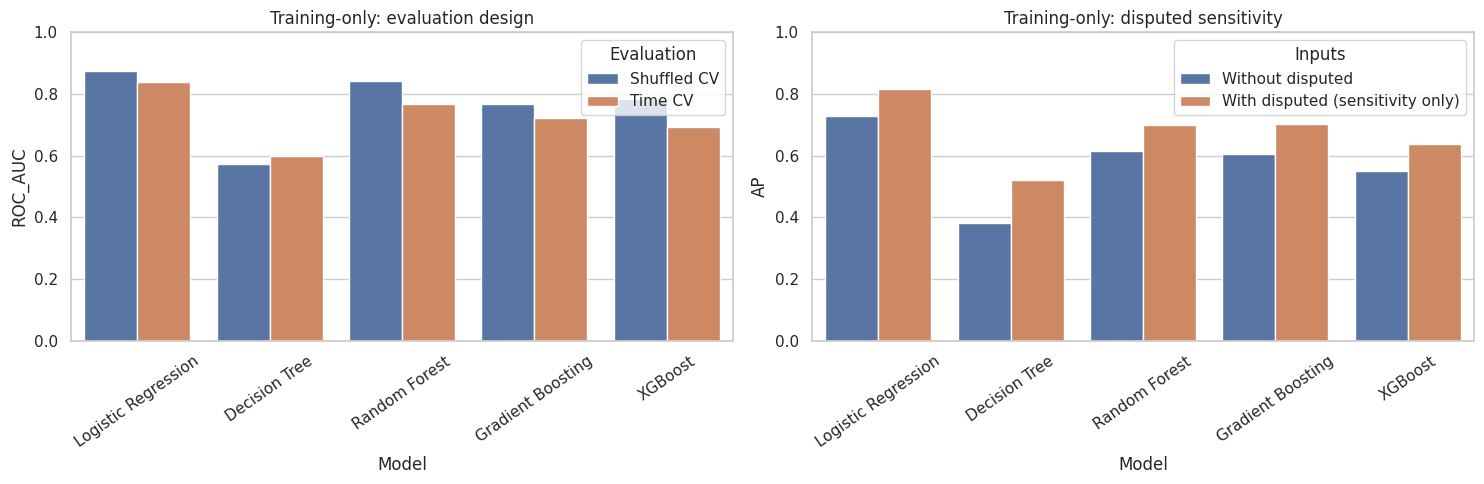

In [35]:
random_cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
robust_rows=[];dispute_rows=[]
for name,model in classification_candidates.items():
    for label,folds in [('Shuffled CV',random_cv),('Time CV',cv_folds)]:
        res=cross_validate(make_pipeline(model),X_train,y_train,cv=folds,scoring='roc_auc',n_jobs=N_JOBS)
        robust_rows.append({'Model':name,'Evaluation':label,'ROC_AUC':res['test_score'].mean()})
    for with_dispute in [False,True]:
        cats=categorical_features+(['Disputed'] if with_dispute else [])
        res=cross_validate(make_pipeline(model,cats,numeric_features),train[cats+numeric_features],y_train,
                          cv=cv_folds,scoring='average_precision',n_jobs=N_JOBS)
        dispute_rows.append({'Model':name,'Inputs':'With disputed (sensitivity only)' if with_dispute else 'Without disputed','AP':res['test_score'].mean()})
robustness=pd.DataFrame(robust_rows);dispute_comparison=pd.DataFrame(dispute_rows)
display(robustness.round(4));display(dispute_comparison.round(4))
fig,axes=plt.subplots(1,2,figsize=(15,5))
sns.barplot(data=robustness,x='Model',y='ROC_AUC',hue='Evaluation',ax=axes[0]);axes[0].set_title('Training-only: evaluation design')
sns.barplot(data=dispute_comparison,x='Model',y='AP',hue='Inputs',ax=axes[1]);axes[1].set_title('Training-only: disputed sensitivity')
for ax in axes:ax.tick_params(axis='x',rotation=35);ax.set_ylim(0,1)
plt.tight_layout();plt.show()

## 14. Overfitting check

**What we have:** Grid-search mean training and forward-CV scores.

**What we need to know:** Are models much stronger on records they fitted than on later records?

**Steps and why:** Compare training AP with CV AP and training MAE with CV MAE for each selected configuration.

**How to read the output:** A larger gap suggests poorer generalisation, but the gap also includes temporal change and sample-size effects. Choosing hyperparameters from CV introduces selection optimism. This is a diagnostic, not proof of a single cause or a confidence interval.

,Model,Mean_train_AP,Best_CV_AP,Train_minus_CV_AP
0,Logistic Regression,0.9287,0.7446,0.1840
1,Decision Tree,0.5721,0.4468,0.1252
2,Random Forest,0.9523,0.7035,0.2489
3,Gradient Boosting,0.8807,0.6858,0.1949
4,XGBoost,0.8828,0.5993,0.2836


,Model,Mean_train_MAE,Best_CV_MAE_days,CV_minus_train_MAE
0,Ridge,2.3164,2.6571,0.3407
1,Random Forest Regressor,2.1381,3.0243,0.8862
2,Gradient Boosting Regressor,2.1827,3.0701,0.8875


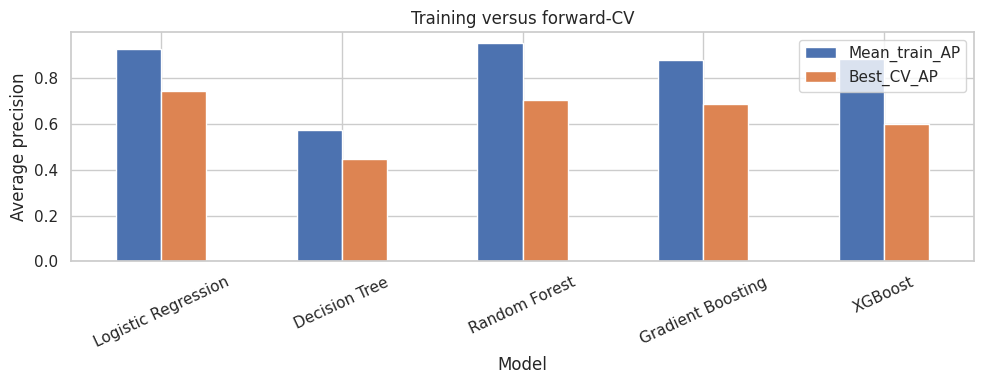

**Output and conclusion:** A high training score alone is not enough. Imbalance describes class counts; overfitting describes failure to generalise. We cannot conclude that imbalance caused a gap simply because both are present.

In [36]:
gap=classification_search_summary[['Model','Mean_train_AP','Best_CV_AP']].copy()
gap['Train_minus_CV_AP']=gap.Mean_train_AP-gap.Best_CV_AP
display(gap.round(4))
reg_gap=regression_search_summary[['Model','Mean_train_MAE','Best_CV_MAE_days']].copy()
reg_gap['CV_minus_train_MAE']=reg_gap.Best_CV_MAE_days-reg_gap.Mean_train_MAE
display(reg_gap.round(4))
gap.set_index('Model')[['Mean_train_AP','Best_CV_AP']].plot.bar(figsize=(10,4));plt.ylabel('Average precision');plt.title('Training versus forward-CV');plt.xticks(rotation=25);plt.tight_layout();plt.show()
explain('A high training score alone is not enough. Imbalance describes class counts; overfitting describes failure to generalise. We cannot conclude that imbalance caused a gap simply because both are present.')

## 15. Final comparison on the fixed test period

**What we have:** Models, hyperparameters and thresholds already selected without this run’s test scores.

**What we need to know:** How do all frozen models perform on later invoices?

**Steps and why:** Evaluate all classifiers and regressors once; include baselines, confusion matrices, ROC/PR and regression diagnostics. Keep the validation-selected defaults even if a different model tops the test table.

**How to read the output:** These are revised results on the previously used test period, not an entirely unseen external dataset. The classification and regression outputs are separate; likely-on-time can coexist with a small positive delay estimate. No model is selected or retuned from this section.

              precision    recall  f1-score   support

     On time       0.90      0.80      0.85       358
        Late       0.61      0.77      0.68       142

    accuracy                           0.80       500
   macro avg       0.76      0.79      0.77       500
weighted avg       0.82      0.80      0.80       500



,Model,Threshold,AP,ROC_AUC,Precision,Recall,F1,Accuracy
0,Logistic Regression,0.3704,0.7052,0.8678,0.6791,0.6408,0.6594,0.812
1,Decision Tree,0.3329,0.4180,0.6104,0.5942,0.2887,0.3886,0.742
2,Random Forest,0.2767,0.6982,0.8443,0.6129,0.8028,0.6951,0.800
3,Gradient Boosting,0.3353,0.6502,0.8160,0.6391,0.5986,0.6182,0.790
4,XGBoost,0.2881,0.7176,0.8695,0.6111,0.7746,0.6832,0.796
5,Dummy baseline,0.5000,0.2840,0.5000,0.0000,0.0000,0.0000,0.716


,Model,MAE,RMSE,R2,Late_only_MAE
0,Ridge,2.2875,3.8998,0.3203,4.4338
1,Random Forest Regressor,2.3527,4.0181,0.2784,4.9958
2,Gradient Boosting Regressor,2.6552,4.1604,0.2264,5.1020
3,Median baseline,2.2840,5.2528,-0.2331,8.0423


**Output and conclusion:** For the validation-selected XGBoost, test AP=0.7176, precision=61.1%, recall=77.5%, F1=0.6832. It finds 110 of 142 late invoices, misses 32, and raises 70 false alerts. 100.0% of test invoices are from known customers.

**Output and conclusion:** The selected Random Forest Regressor has MAE=2.353 days and late-only MAE=4.996 days. Median baseline MAE=2.284; improvement is -0.069 days. Positive improvement means lower error, negative means worse. These average errors are not prediction intervals.

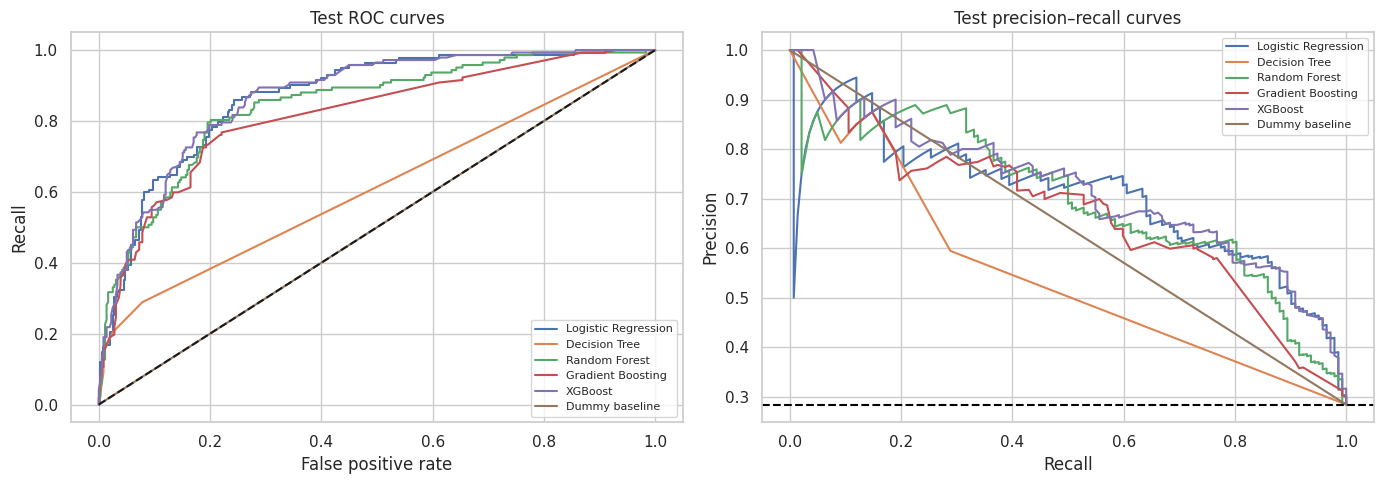

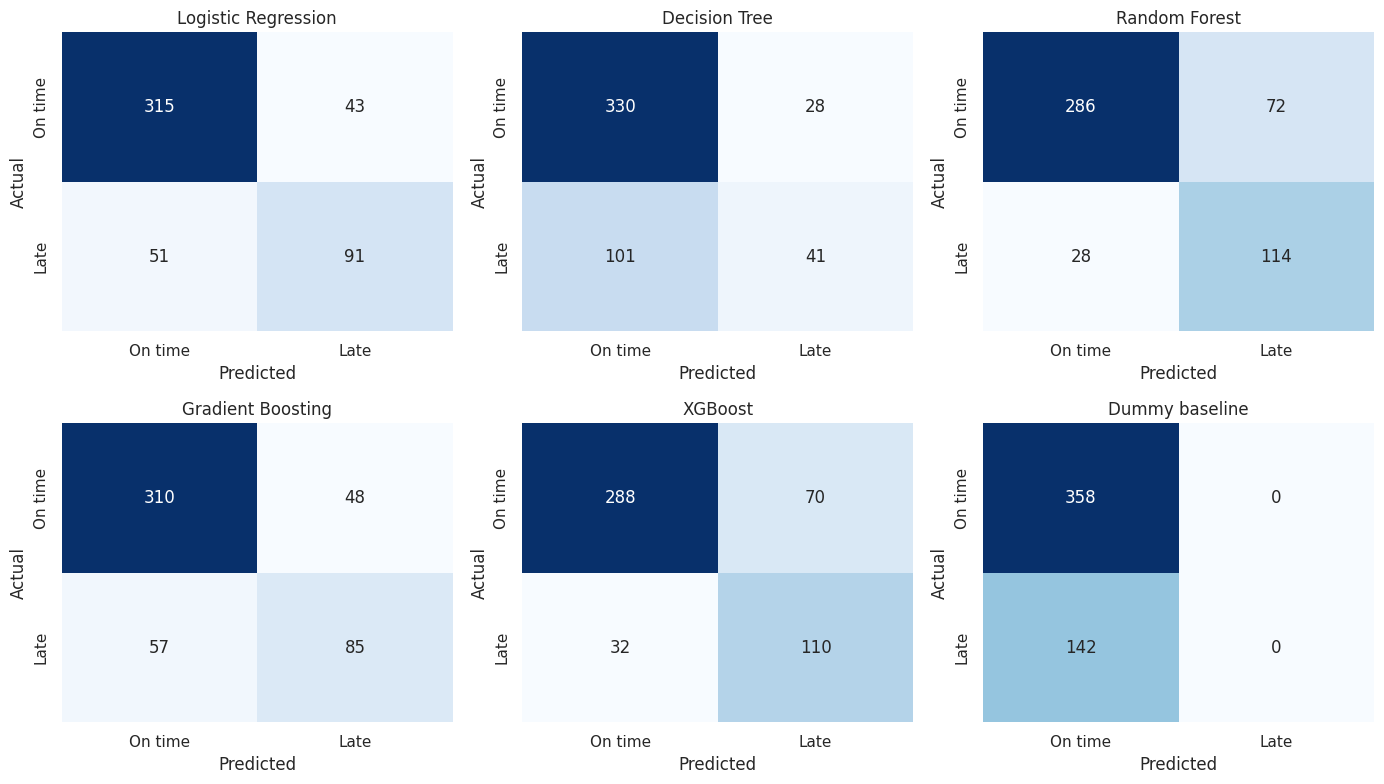

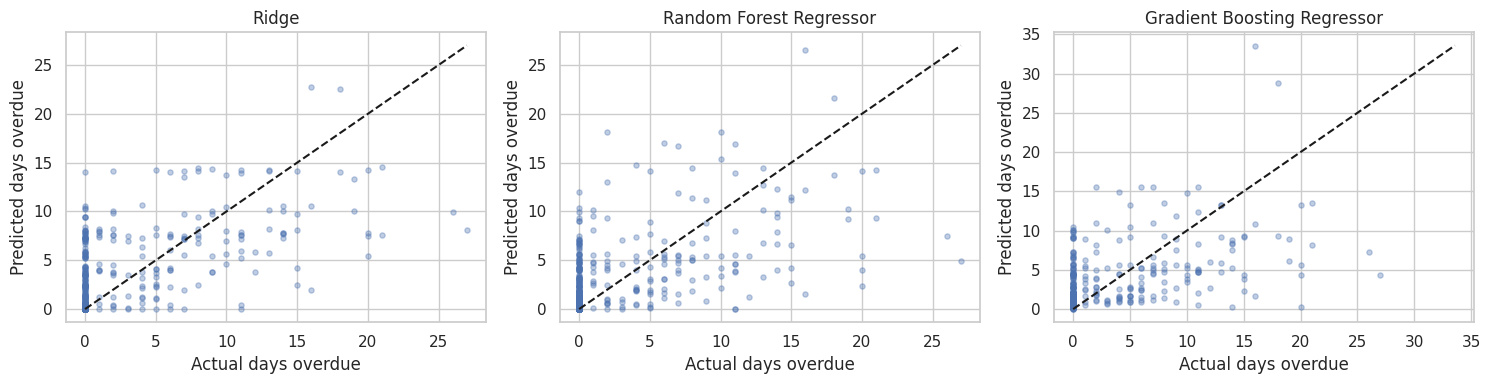

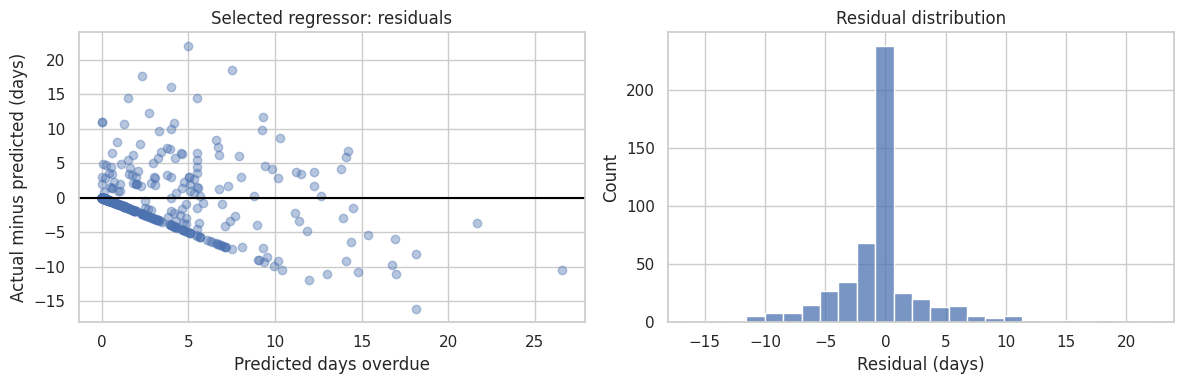

**Output and conclusion:** Points near the diagonal indicate accurate delay estimates. Positive residuals mean underprediction. If large actual delays are systematically underestimated, the model is less useful for severe cases even with a small overall MAE.

**Output and conclusion:** Validation AP for the default classifier was 0.8006; test AP is 0.7176. Assess this with the earlier training/CV gaps and changing class prevalence rather than assigning the change to imbalance alone. The validation-selected models remain the defaults even if another model has better test metrics.

In [37]:
classification_test=pd.DataFrame([{'Model':n,'Threshold':thresholds_by_model[n],
    **classification_metrics(y_test,m.predict_proba(X_test)[:,1],thresholds_by_model[n])} for n,m in classification_models.items()])
regression_test=pd.DataFrame([{'Model':n,**regression_metrics(r_test,m.predict(X_test))} for n,m in regression_models.items()])
display(classification_test.round(4));display(regression_test.round(4))
selected_c=classification_test.set_index('Model').loc[best_classifier_name]
selected_r=regression_test.set_index('Model').loc[best_regressor_name]
test_probability=best_classifier.predict_proba(X_test)[:,1]
test_prediction=(test_probability>=best_threshold).astype(int)
test_delay=np.maximum(0,best_regressor.predict(X_test))
cm=confusion_matrix(y_test,test_prediction)
print(classification_report(y_test,test_prediction,target_names=['On time','Late'],zero_division=0))
known=test.customerID.isin(train.customerID).mean()
explain(f"For the validation-selected {best_classifier_name}, test AP={selected_c.AP:.4f}, precision={selected_c.Precision:.1%}, recall={selected_c.Recall:.1%}, F1={selected_c.F1:.4f}. It finds {cm[1,1]} of {int(y_test.sum())} late invoices, misses {cm[1,0]}, and raises {cm[0,1]} false alerts. {known:.1%} of test invoices are from known customers.")
baseline_r=regression_test.set_index('Model').loc['Median baseline']
explain(f"The selected {best_regressor_name} has MAE={selected_r.MAE:.3f} days and late-only MAE={selected_r.Late_only_MAE:.3f} days. Median baseline MAE={baseline_r.MAE:.3f}; improvement is {baseline_r.MAE-selected_r.MAE:.3f} days. Positive improvement means lower error, negative means worse. These average errors are not prediction intervals.")
fig,axes=plt.subplots(1,2,figsize=(14,5))
for name,m in classification_models.items():
    p=m.predict_proba(X_test)[:,1];fpr,tpr,_=roc_curve(y_test,p);pr,re,_=precision_recall_curve(y_test,p)
    axes[0].plot(fpr,tpr,label=name);axes[1].plot(re,pr,label=name)
axes[0].plot([0,1],[0,1],'k--');axes[0].set(xlabel='False positive rate',ylabel='Recall',title='Test ROC curves')
axes[1].axhline(y_test.mean(),color='black',ls='--');axes[1].set(xlabel='Recall',ylabel='Precision',title='Test precision–recall curves')
for ax in axes:ax.legend(fontsize=8)
plt.tight_layout();save_fig('21_test_curves');plt.show()
fig,axes=plt.subplots(2,3,figsize=(14,8))
for ax,(name,m) in zip(axes.ravel(),classification_models.items()):
    z=m.predict_proba(X_test)[:,1]>=thresholds_by_model[name]
    sns.heatmap(confusion_matrix(y_test,z),annot=True,fmt='d',cbar=False,cmap='Blues',ax=ax,xticklabels=['On time','Late'],yticklabels=['On time','Late'])
    ax.set(title=name,xlabel='Predicted',ylabel='Actual')
plt.tight_layout();save_fig('22_test_confusion');plt.show()
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,(name,m) in zip(axes,[(n,m) for n,m in regression_models.items() if n!='Median baseline']):
    pred=np.maximum(0,m.predict(X_test));ax.scatter(r_test,pred,alpha=.35,s=14)
    upper=max(r_test.max(),pred.max());ax.plot([0,upper],[0,upper],'k--');ax.set(title=name,xlabel='Actual days overdue',ylabel='Predicted days overdue')
plt.tight_layout();save_fig('23_regression_scatter');plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4));residual=r_test.to_numpy()-test_delay
axes[0].scatter(test_delay,residual,alpha=.4);axes[0].axhline(0,color='black');axes[0].set(xlabel='Predicted days overdue',ylabel='Actual minus predicted (days)',title='Selected regressor: residuals')
sns.histplot(residual,ax=axes[1],bins=25);axes[1].set(xlabel='Residual (days)',title='Residual distribution')
plt.tight_layout();plt.show()
explain('Points near the diagonal indicate accurate delay estimates. Positive residuals mean underprediction. If large actual delays are systematically underestimated, the model is less useful for severe cases even with a small overall MAE.')
explain(f"Validation AP for the default classifier was {float(classification_validation.set_index('Model').loc[best_classifier_name,'AP']):.4f}; test AP is {selected_c.AP:.4f}. Assess this with the earlier training/CV gaps and changing class prevalence rather than assigning the change to imbalance alone. The validation-selected models remain the defaults even if another model has better test metrics.")


## 16. Coefficients, feature importance and how scores are calculated

**What we have:** Fitted Logistic Regression, Ridge and tree pipelines.

**What we need to know:** What does a model output mean mathematically?

**Steps and why:** Inspect actual fitted coefficients and transformed inputs. Reconstruct the Logistic Regression score using the sigmoid and the Ridge prediction using the weighted sum, and assert they match sklearn.

**How to read the output:** For Logistic Regression, z=intercept+Σβx and score=1/(1+exp(−z)). A positive coefficient raises log-odds while holding other encoded inputs fixed; exp(β) is the corresponding odds multiplier. It is not an increase of β percentage points. A one-unit change in scaled amount is one training standard deviation. Full one-hot encoding with regularisation makes individual category coefficients parameterisation-dependent; they are not causal effects.

Logistic Regression intercept: -0.8407329082390027
Ridge intercept: 3.4181573056241983


,feature,coefficient_log_odds,odds_multiplier,abs_coefficient
4,categories__customerID_0688-XNJRO,5.734340,309.308810,5.734340
78,categories__customerID_8690-EEBEO,4.377683,79.653295,4.377683
56,categories__customerID_6708-DPYTF,4.065645,58.302527,4.065645
74,categories__customerID_8102-ABPKQ,3.863030,47.609403,3.863030
96,categories__customerID_9771-QTLGZ,-3.821484,0.021895,3.821484
43,categories__customerID_5613-UHVMG,3.787836,44.160737,3.787836
12,categories__customerID_1604-LIFKX,3.691304,40.097095,3.691304
62,categories__customerID_7245-CKNCN,-3.628962,0.026544,3.628962
91,categories__customerID_9322-YCTQO,3.566566,35.394823,3.566566
61,categories__customerID_7228-LEPPM,3.564838,35.333735,3.564838


,feature,coefficient_days,abs_coefficient
17,categories__customerID_2621-XCLEH,18.794718,18.794718
4,categories__customerID_0688-XNJRO,12.596945,12.596945
43,categories__customerID_5613-UHVMG,11.146202,11.146202
12,categories__customerID_1604-LIFKX,10.873488,10.873488
74,categories__customerID_8102-ABPKQ,8.261404,8.261404
61,categories__customerID_7228-LEPPM,7.994931,7.994931
69,categories__customerID_7758-WKLVM,7.258258,7.258258
56,categories__customerID_6708-DPYTF,7.114995,7.114995
84,categories__customerID_9117-LYRCE,7.113090,7.113090
32,categories__customerID_4460-ZXNDN,6.904158,6.904158


,logit_z,manual_sigmoid_score,sklearn_score,LR_threshold,LR_class,Ridge_raw_days,Ridge_clipped_days
0,2.45954,0.921256,0.921256,0.370408,1,8.005666,8.005666


**Output and conclusion:** The sigmoid produces a number between zero and one. Without calibration evidence we call it a model risk score, not a guaranteed real-world probability. Tree classifiers use leaf class proportions (with smoothing/weighting effects as applicable); Random Forest averages tree probabilities. Boosting combines learned contributions into a classification score. Ridge outputs a number of days, not a probability.

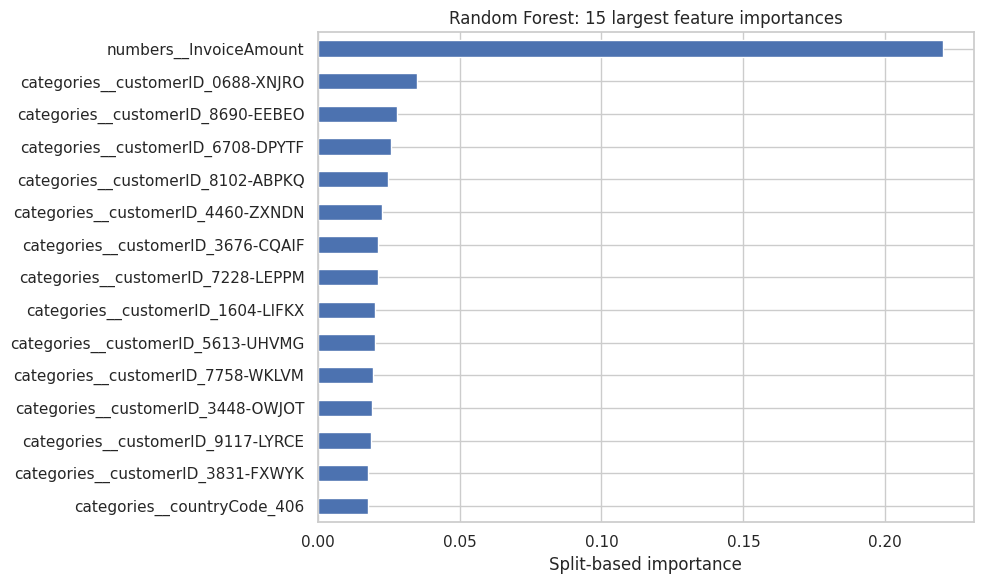

**Output and conclusion:** Tree importances are nonnegative and sum to one, but do not give effect direction or causality. Importance can favour high-cardinality information such as customer identity; correlated features can share it.

,Model,Calculation,Reconstructed_score,predict_proba_score
0,Logistic Regression,sigmoid of decision score,0.921256,0.921256
1,Decision Tree,late proportion in reached leaf,0.166144,0.166144
2,Random Forest,mean of tree leaf probabilities,0.692792,0.692792
3,Gradient Boosting,sigmoid of decision score,0.566151,0.566151
4,XGBoost,sigmoid of boosted raw margin,0.612903,0.612903


**Output and conclusion:** These matching values verify how each model computes its score for the example. If class weighting is used, leaf proportions and fitted scores reflect those weights. Matching the mathematical calculation is not evidence that the scores are calibrated real-world probabilities.

In [38]:
def selected_feature_names(pipeline):
    names=pipeline.named_steps['preprocess'].get_feature_names_out()
    return names[pipeline.named_steps['select'].get_support()]
lr=classification_models['Logistic Regression'];ridge=regression_models['Ridge']
lr_table=pd.DataFrame({'feature':selected_feature_names(lr),'coefficient_log_odds':lr.named_steps['model'].coef_[0]})
lr_table['odds_multiplier']=np.exp(lr_table.coefficient_log_odds)
lr_table['abs_coefficient']=lr_table.coefficient_log_odds.abs()
print('Logistic Regression intercept:',lr.named_steps['model'].intercept_[0])
display(lr_table.sort_values('abs_coefficient',ascending=False).head(15))
ridge_table=pd.DataFrame({'feature':selected_feature_names(ridge),'coefficient_days':ridge.named_steps['model'].coef_})
print('Ridge intercept:',ridge.named_steps['model'].intercept_)
display(ridge_table.assign(abs_coefficient=lambda x:x.coefficient_days.abs()).sort_values('abs_coefficient',ascending=False).head(15))
example=X_test.iloc[[0]]
x_lr=lr[:-1].transform(example);z=float((x_lr@lr.named_steps['model'].coef_.T).item()+lr.named_steps['model'].intercept_[0])
p_manual=float(expit(z));p_library=float(lr.predict_proba(example)[0,1])
x_r=ridge[:-1].transform(example);r_manual=float((x_r@ridge.named_steps['model'].coef_).item()+ridge.named_steps['model'].intercept_)
np.testing.assert_allclose(p_manual,p_library);np.testing.assert_allclose(r_manual,ridge.predict(example)[0])
display(pd.DataFrame([{'logit_z':z,'manual_sigmoid_score':p_manual,'sklearn_score':p_library,'LR_threshold':thresholds_by_model['Logistic Regression'],'LR_class':int(p_manual>=thresholds_by_model['Logistic Regression']),'Ridge_raw_days':r_manual,'Ridge_clipped_days':max(0,r_manual)}]))
explain('The sigmoid produces a number between zero and one. Without calibration evidence we call it a model risk score, not a guaranteed real-world probability. Tree classifiers use leaf class proportions (with smoothing/weighting effects as applicable); Random Forest averages tree probabilities. Boosting combines learned contributions into a classification score. Ridge outputs a number of days, not a probability.')
# Tree importance: training-derived split importance, not an independent relevance test.
rf_pipeline=classification_models['Random Forest']
importance=pd.Series(rf_pipeline.named_steps['model'].feature_importances_,index=selected_feature_names(rf_pipeline)).sort_values()
importance.tail(15).plot.barh(figsize=(10,6));plt.xlabel('Split-based importance');plt.title('Random Forest: 15 largest feature importances');plt.tight_layout();plt.show()
explain('Tree importances are nonnegative and sum to one, but do not give effect direction or causality. Importance can favour high-cardinality information such as customer identity; correlated features can share it.')
# Reconstruct probability-shaped outputs for all five classifier families.
probability_mechanics=[]
for name,pipeline in classification_models.items():
    if name=='Dummy baseline': continue
    transformed=pipeline[:-1].transform(example)
    estimator=pipeline.named_steps['model']
    if name in ['Logistic Regression','Gradient Boosting']:
        internal=float(np.asarray(estimator.decision_function(transformed)).ravel()[0])
        reconstructed=float(expit(internal));method='sigmoid of decision score'
    elif name=='XGBoost':
        internal=float(estimator.predict(transformed,output_margin=True)[0])
        reconstructed=float(expit(internal));method='sigmoid of boosted raw margin'
    elif name=='Random Forest':
        reconstructed=float(np.mean([tree.predict_proba(transformed)[0,1] for tree in estimator.estimators_]))
        method='mean of tree leaf probabilities'
    else:
        leaf=int(estimator.apply(transformed)[0]);values=estimator.tree_.value[leaf][0]
        reconstructed=float(values[1]/values.sum());method='late proportion in reached leaf'
    actual=float(estimator.predict_proba(transformed)[0,1])
    np.testing.assert_allclose(reconstructed,actual,rtol=1e-5,atol=1e-7)
    probability_mechanics.append({'Model':name,'Calculation':method,'Reconstructed_score':reconstructed,'predict_proba_score':actual})
display(pd.DataFrame(probability_mechanics))
explain('These matching values verify how each model computes its score for the example. If class weighting is used, leaf proportions and fitted scores reflect those weights. Matching the mathematical calculation is not evidence that the scores are calibrated real-world probabilities.')


## 17. Probability calibration and follow-up priority

**What we have:** Test risk scores and actual outcomes.

**What we need to know:** Do score bands match observed frequencies, and can ranking help follow-up?

**Steps and why:** Plot a diagnostic reliability curve and risk deciles. These are descriptive test diagnostics only; no thresholds or calibration model are fitted from them.

**How to read the output:** A score of 0.7 is not automatically a proven 70% real-world chance. Calibration compares mean scores with observed event rates. A lift chart shows concentration of late invoices among high-scoring groups; it is not a deployment guarantee.

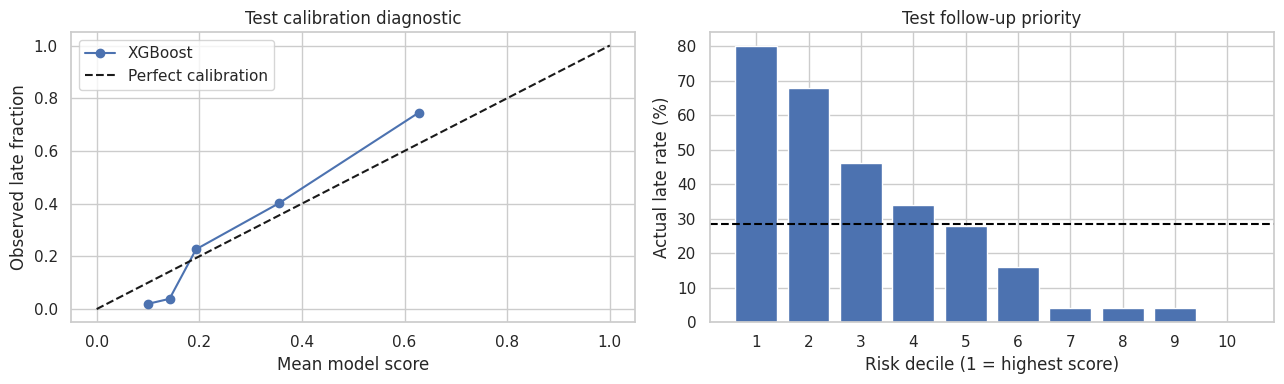

,invoices,late_rate,late_count,cumulative_share_of_late
decile,,,,
1,50,0.80,40,0.2817
2,50,0.68,34,0.5211
3,50,0.46,23,0.6831
4,50,0.34,17,0.8028
5,50,0.28,14,0.9014
6,50,0.16,8,0.9577
7,50,0.04,2,0.9718
8,50,0.04,2,0.9859
9,50,0.04,2,1.0000


**Output and conclusion:** The highest-scoring 20% contain 52.1% of test late invoices. This is a descriptive ranking result; ties are split by row order and the observed population is company-specific.

In [39]:
frac_pos,mean_pred=calibration_curve(y_test,test_probability,n_bins=5,strategy='quantile')
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].plot(mean_pred,frac_pos,'o-',label=best_classifier_name);axes[0].plot([0,1],[0,1],'k--',label='Perfect calibration');axes[0].set(xlabel='Mean model score',ylabel='Observed late fraction',title='Test calibration diagnostic');axes[0].legend()
dec=pd.DataFrame({'score':test_probability,'late':y_test.to_numpy()})
dec['decile']=pd.qcut(dec.score.rank(method='first',ascending=False),10,labels=range(1,11))
lift=dec.groupby('decile',observed=True).agg(invoices=('late','size'),late_rate=('late','mean'),late_count=('late','sum'))
lift['cumulative_share_of_late']=lift.late_count.cumsum()/lift.late_count.sum()
axes[1].bar(lift.index.astype(str),100*lift.late_rate);axes[1].axhline(100*y_test.mean(),color='black',ls='--');axes[1].set(xlabel='Risk decile (1 = highest score)',ylabel='Actual late rate (%)',title='Test follow-up priority')
plt.tight_layout();save_fig('24_calibration_lift');plt.show();display(lift.round(4))
explain(f'The highest-scoring 20% contain {lift.iloc[1].cumulative_share_of_late:.1%} of test late invoices. This is a descriptive ranking result; ties are split by row order and the observed population is company-specific.')

## 18. What the final prototype will show

**What we have:** All fitted models in memory, their thresholds, validation/test comparisons and raw invoice fields.

**What we need to know:** How do invoice details become two predictions?

**Steps and why:** For a supported customer, feed raw fields through the selected classifier’s and regressor’s fitted preprocessing/selection pipelines. Apply that classifier’s threshold and clip negative delay estimates to zero.

**How to read the output:** OCR only extracts text; it does not learn payment behaviour. Users must review extraction. The code below demonstrates scoring for every model on the same held-out invoice. It is not a deployed app, and no model exports are performed in this notebook.

In [40]:
sample=test.iloc[[0]]
print('Example invoice:',sample[['invoiceNumber','customerID','countryCode','PaperlessBill','InvoiceAmount','InvoiceDate','DueDate']].to_dict('records')[0])
demo_class=[]
for name,model in classification_models.items():
    p=float(model.predict_proba(sample[features])[0,1]);t=thresholds_by_model[name]
    demo_class.append({'Model':name,'Risk_score':p,'Threshold':t,'Prediction':'Late' if p>=t else 'On time'})
display(pd.DataFrame(demo_class))
display(pd.DataFrame([{'Model':name,'Estimated_days_overdue':float(max(0,model.predict(sample[features])[0]))} for name,model in regression_models.items()]))
print('Recorded outcome (revealed only for demonstration):',int(sample.is_late.iloc[0]),'Actual days overdue:',int(sample.days_overdue.iloc[0]))
# One table makes the post-selection result easy to use in a report later.
comparison_summary={'classifier':best_classifier_name,'regressor':best_regressor_name,
    'threshold':best_threshold,'classification_test':selected_c.to_dict(),'regression_test':selected_r.to_dict()}
explain('For deployment later, the app must load the exact pipelines, per-model thresholds and input schema from this run. This run includes payment terms as a candidate that is removed by the variance filter; the future app must derive it from issue/due dates or explicitly use the sample-data 30-day convention. Do not silently feed arbitrary real invoices through that convention.')

Example invoice: {'invoiceNumber': 1281718631, 'customerID': '9322-YCTQO', 'countryCode': '406', 'PaperlessBill': 'Electronic', 'InvoiceAmount': 92.35, 'InvoiceDate': Timestamp('2013-07-12 00:00:00'), 'DueDate': Timestamp('2013-08-11 00:00:00')}
Recorded outcome (revealed only for demonstration): 1 Actual days overdue: 1


,Model,Risk_score,Threshold,Prediction
0,Logistic Regression,0.921256,0.370408,Late
1,Decision Tree,0.166144,0.332902,On time
2,Random Forest,0.692792,0.276737,Late
3,Gradient Boosting,0.566151,0.335287,Late
4,XGBoost,0.612903,0.288087,Late
5,Dummy baseline,0.374101,0.500000,On time


,Model,Estimated_days_overdue
0,Ridge,8.005666
1,Random Forest Regressor,5.493282
2,Gradient Boosting Regressor,4.229868
3,Median baseline,0.000000


**Output and conclusion:** For deployment later, the app must load the exact pipelines, per-model thresholds and input schema from this run. This run includes payment terms as a candidate that is removed by the variance filter; the future app must derive it from issue/due dates or explicitly use the sample-data 30-day convention. Do not silently feed arbitrary real invoices through that convention.

## 19. Previous prototype results — reference only
These figures are from the earlier submitted notebook's fixed-parameter final pipeline. They are retained so the original findings are not lost. **They are not the new GridSearchCV results above.**

| Earlier classifier | Validation AP | ROC-AUC | Precision at 0.5 | Recall at 0.5 | F1 at 0.5 |
|---|---:|---:|---:|---:|---:|
| Logistic Regression ordinary | .7974 | .8967 | .8039 | .6308 | .7069 |
| Logistic Regression balanced | .7971 | .8969 | .7442 | .7385 | .7413 |
| Random Forest ordinary | .7936 | .8806 | .8769 | .4385 | .5846 |
| Random Forest balanced | .7821 | .8764 | .7755 | .5846 | .6667 |
| XGBoost ordinary | .7802 | .8768 | .8852 | .4154 | .5654 |
| XGBoost balanced | .7732 | .8763 | .7917 | .5846 | .6726 |
| Dummy | .3178 | .5000 | 0 | 0 | 0 |

Earlier default: ordinary Logistic Regression, threshold approximately .323, with test AP .7053, ROC-AUC .8692, precision .6337, recall .7676 and F1 .6943. Confusion matrix: [[295,63],[33,109]]. Only that model's threshold was tuned at the time; the revised notebook tunes every classifier threshold.

| Earlier regressor | Validation MAE | RMSE | R² | Late-only MAE |
|---|---:|---:|---:|---:|
| Ridge | 2.7469 | 5.0350 | .3675 | 5.9449 |
| Random Forest | 2.7831 | 5.0466 | .3646 | 5.9729 |
| Median baseline | 3.1271 | 7.0612 | −.2440 | 9.8385 |
| Gradient Boosting | 3.5441 | 5.4795 | .2509 | 6.2844 |

Earlier Ridge test: MAE 2.2624, RMSE 3.8362, R² .3423 and late-only MAE 4.3461. Median baseline test MAE was 2.2840, so the overall improvement was small. The earlier random-CV feature-set results included different inputs/evaluation assumptions and are not comparable with the corrected chronological results.

## 20. Conclusions, limits and viva guide
### Actual result from this executed revision
- **Feature selection:** 109 encoded candidate columns became 108 after removing constant payment terms. The five raw candidate fields contain only four varying input fields in this sample.
- **Classifier selected by validation AP:** XGBoost, learning rate 0.1, max depth 3 and 200 trees. Validation AP 0.8006 versus Logistic Regression 0.7959 is a small lead, not proof of universal superiority. Its validation-F1 threshold is approximately 0.2881.
- **Regressor selected by validation MAE:** Random Forest, 100 trees, no explicit maximum depth and minimum leaf size 2. Validation MAE was 2.7255 days versus Ridge 2.7352: again a small difference.
- **Test classification:** selected XGBoost AP 0.7176, recall 0.7746, precision 0.6111 and F1 0.6832. It found 110 late invoices, missed 32 and gave 70 false alerts. Logistic Regression had higher precision at its own threshold, while Random Forest had higher recall. The right trade-off depends on follow-up costs.
- **Test regression:** selected Random Forest MAE 2.3527 days was worse than the median baseline's 2.2840. Its RMSE and late-only MAE were better than baseline. We therefore cannot claim an overall MAE improvement. Ridge had better test MAE than the forest, but we did not switch defaults after seeing the test results.
- **Different winners from the original prototype:** the candidate settings were tuned under a new time-CV protocol. The earlier Logistic Regression/Ridge results remain in Section 19 as historical results. More tuning does not guarantee better test performance.

**What the run establishes:** the executed comparisons above show which configurations performed best under this dataset, these candidate grids and these time boundaries. The simple model need not always win, and a complex model need not be better. We report both strengths and errors.

**Limits:** sample/synthetic data; known customers; no permanent defaults; small sample; historical test period previously inspected; outcome-availability filtering excludes some outstanding invoices; customer-history experiments assume rolling ledger access; uncalibrated risk scores; no independent company dataset. There is no evidence that class imbalance alone caused overfitting.

**Next steps:** review the fitted results, update the app to support all selected pipelines and comparisons, then write the report in the supplied lab format. Later use real authorised company records, independent later periods, new-customer tests and calibration assessed without reusing the final test set.

### Short viva answers
- **Why classification and regression?** One estimates whether payment is late; the other estimates delay magnitude.
- **Why 60/20/20?** Practical allocation of data to learning, selection and evaluation; time ordering is more important than a particular ratio.
- **Why exclude 167 rows originally?** Their outcomes were unknown at the relevant boundary, not because their class was inconvenient.
- **What is payment terms?** Due date minus issue date; all original records allowed 30 days. It is not the actual payment delay.
- **Why not use DaysLate as input?** It contains the answer. It may define a target but cannot be used to predict that target at issue time.
- **Have we done binning?** Yes, delay ranges and amount quintiles for exploration; the model retains continuous amount information.
- **What feature-selection method?** VarianceThreshold removes constant transformed features, fitted within each training fold. It is a basic filter, not an importance ranking.
- **What if we use another split?** Counts, class prevalence and learned parameters may change. We inspect allocation sensitivity, but do not select a split to inflate test scores.
- **Is 0.323 still our threshold?** Only for the earlier prototype. Use the actual per-model thresholds printed by this run.
- **What does C or alpha mean?** Smaller LR C and larger Ridge alpha impose stronger regularisation.
- **Does 80% recall mean 80% accuracy?** No. Recall covers actual late invoices; accuracy covers every invoice.
- **Is a score a guarantee?** No. The probability-shaped score requires calibration and validation before being interpreted as a reliable real-world frequency.
- **What is our contribution?** Explain the work each member actually performed; do not claim work you cannot explain.

### References
1. Dataset: https://www.kaggle.com/datasets/hhenry/finance-factoring-ibm-late-payment-histories
2. Original team notebook: risk-invoice-detection (2).ipynb; this revision preserves its analysis questions and records corrections.
3. GridSearchCV: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
4. Feature selection: https://scikit-learn.org/stable/modules/feature_selection.html
5. Cross-validation: https://scikit-learn.org/stable/modules/cross_validation.html
6. Logistic Regression and Ridge: https://scikit-learn.org/stable/modules/linear_model.html
7. Model evaluation: https://scikit-learn.org/stable/modules/model_evaluation.html
8. XGBoost: https://xgboost.readthedocs.io/en/stable/python/python_api.html
9. SMOTE: https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html

Before submission: fill the missing roll number, read and personalise the interpretations, record real member contributions and follow the institution's referencing/disclosure rules. Do not promise a Turnitin or AI-detection score.

In [41]:
# Execution checks: these must pass after Restart & Run All.
assert len(classification_searches)>=3 and len(regression_searches)>=3
assert all(isinstance(s,GridSearchCV) for s in classification_searches.values())
assert 'numbers__payment_terms_days' in encoded[~support]
assert not set(['DaysLate','DaysToSettle','SettledDate','is_late','days_overdue']).intersection(features)
assert set(classification_models)==set(thresholds_by_model)
assert np.isfinite(classification_test.select_dtypes('number')).all().all()
assert np.isfinite(regression_test.select_dtypes('number')).all().all()
print('All execution checks passed. No model-export cells were run or included.')
print('Name/roll-number action: fill Vanshika’s roll number before submission.')
print('Default classifier:',best_classifier_name,'Default regressor:',best_regressor_name)

All execution checks passed. No model-export cells were run or included.
Name/roll-number action: fill Vanshika’s roll number before submission.
Default classifier: XGBoost Default regressor: Random Forest Regressor
